# Домашнее задание 1. Данные и baseline

**Автор:** Галлаб Абдуллах
**Датасет:** Bank Marketing (UCI)

In [69]:
!wget -q https://archive.ics.uci.edu/static/public/222/bank+marketing.zip -O bank.zip
!unzip -o -q bank.zip
!unzip -o -q bank-additional.zip
!ls bank-additional

bank-additional.csv  bank-additional-full.csv  bank-additional-names.txt


## 0. Загрузка данных

In [70]:
import numpy as np
import pandas as pd

df = pd.read_csv('bank-additional/bank-additional-full.csv' , sep= ';')
df.shape

(41188, 21)

## 1. Описание данных

- Смотрим на первые строки

- Посмотрим типы столбцов :

In [71]:
df.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

### 1.1 Источник

**Датасет:** Bank Marketing, UCI Machine Learning Repository.

**Что это за данные.** Португальский банк проводил телефонные кампании: операторы звонили клиентам и предлагали открыть **срочный вклад** (депозит на фиксированный срок под фиксированный процент). Каждая строка — один контакт с клиентом, период с мая 2008 по ноябрь 2010. Часть этого периода пришлась на мировой финансовый кризис, поэтому в данные добавлены макроэкономические показатели.

### 1.2 Размер

- Объектов: $ n= 41188$
- Признаков: $d = 20$
- Целевая переменная: `y`

### 1.3 Признаки

**Данные о клиенте**

| Признак | Что означает | Тип | Единицы / значения |
|---|---|---|---|
| `age` | возраст клиента | Integer | годы |
| `job` | профессия | Categorical | 12 значений (admin., technician, student, retired, …) |
| `marital` | семейное положение | Categorical | married, single, divorced, unknown |
| `education` | уровень образования | Categorical | от basic.4y до university.degree, unknown |
| `default` | есть ли просроченный кредит | Binary | yes, no, unknown |
| `housing` | есть ли ипотека | Binary | yes, no, unknown |
| `loan` | есть ли потребительский кредит | Binary | yes, no, unknown |

**Последний контакт в текущей кампании**

| Признак | Что означает | Тип | Единицы / значения |
|---|---|---|---|
| `contact` | тип связи | Categorical | cellular (мобильный), telephone (стационарный) |
| `month` | месяц контакта | Date | mar … dec |
| `day_of_week` | день недели | Date | mon … fri |
| `duration` | длительность звонка | Integer | секунды |

**История контактов**

| Признак | Что означает | Тип | Единицы / значения |
|---|---|---|---|
| `campaign` | число контактов в этой кампании (включая последний) | Integer | штуки |
| `pdays` | дней с последнего контакта в прошлой кампании | Integer | дни; **999 = раньше не звонили** |
| `previous` | число контактов до этой кампании | Integer | штуки |
| `poutcome` | результат прошлой кампании | Categorical | success, failure, nonexistent |

**Социально-экономический контекст** (одинаков для всех клиентов в один период)

| Признак | Что означает | Тип | Периодичность | Единицы |
|---|---|---|---|---|
| `emp.var.rate` | изменение уровня занятости | float | квартал | % |
| `cons.price.idx` | индекс потребительских цен (инфляция) | float | месяц | индекс |
| `cons.conf.idx` | индекс потребительского доверия (отрицательный = люди настроены пессимистично) | float | месяц | индекс |
| `euribor3m` | ставка Euribor на 3 месяца | float | день | % |
| `nr.employed` | число занятых в экономике | float | квартал | тыс. человек |

**Целевая переменная**

| Признак | Что означает | Значения |
|---|---|---|
| `y` | открыл ли клиент срочный вклад | yes (1), no (0) |


### 1.4 Постановка задачи

Обучающая выборка — матрица признаков и вектор ответов:

$$X \in \mathbb{R}^{n \times d}, \qquad y \in \{0, 1\}^n,$$

где $y_i = 1$, если $i$-й клиент открыл вклад, и $y_i = 0$ иначе.

Нужно найти функцию $a(x)$, которая по признакам клиента $x$ предсказывает ответ:

$$a: \mathbb{R}^{d} \to \{0, 1\}, \qquad a(x_i) \approx y_i.$$



### 1.5 Почему задача осмысленна

Каждый звонок стоит денег и времени операторов, а лишние звонки раздражают клиентов и портят отношение к банку. Модель, которая оценивает вероятность согласия **до** звонка, позволяет:

- звонить в первую очередь самым перспективным клиентам и получать больше вкладов при том же числе звонков;
- не беспокоить клиентов с низкой вероятностью согласия;
- понять, какие факторы (профиль клиента, история контактов, экономическая ситуация) влияют на успех кампании.

### 1.6 Особенности данных

1. **Скрытые пропуски:** в `job`, `marital`, `education`, `default`, `housing`, `loan` пропуски записаны строкой `"unknown"`.
2. **Служебное значение `pdays = 999`:** по описанию означает «раньше не звонили», но у 4 110 клиентов при этом `previous > 0`.
3. **Утечка через `duration`:** длительность известна только после звонка, признак исключается из модели.
4. **Временной порядок:** данные упорядочены по времени (2008–2010), что важно при разбиении.






---


---



---







## 2. Обзор

### 2.1 Описательные статистики

- **Статистики по датасете**
: Важные характеристики как среднее значение и медиана и еще другие важные характеристики.

In [73]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


-  **Для категориальных признаков:**

Здесь unique — сколько разных категорий, top — самая частая, freq — сколько раз она встречается.

In [74]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


### 2.2 Пропуски

- ***Проверяем пропуски - строки со значенями unknown***


In [75]:
df.isna().mean() # это функция выводит нули , т.к в датасете пропуски записаны как unknown. Поэтому мы будем по другому получить пропуски.

,0
age,0.0
job,0.0
marital,0.0
education,0.0
default,0.0
housing,0.0
loan,0.0
contact,0.0
month,0.0
day_of_week,0.0


In [76]:
# Заменяем 'unknown' на NaN: pandas распознаёт NaN как пропуск,
# а 'unknown' считает обычной строкой, то есть заполненным значением.
df = df.replace('unknown', np.nan)
df.isna().mean().round(4) * 100

,0
age,0.00
job,0.80
marital,0.19
education,4.20
default,20.87
housing,2.40
loan,2.40
contact,0.00
month,0.00
day_of_week,0.00


### 2.3 Сводная таблица признаков

In [77]:
print('Размер:', df.shape)

overview = pd.DataFrame({
    'тип': df.dtypes,
    'уникальных': df.nunique(),
    'пропусков_%': (df.isna().mean() * 100).round(2),



})
overview

Размер: (41188, 21)


,тип,уникальных,пропусков_%
age,int64,78,0.00
job,object,11,0.80
marital,object,3,0.19
education,object,7,4.20
default,object,2,20.87
housing,object,2,2.40
loan,object,2,2.40
contact,object,2,0.00
month,object,10,0.00
day_of_week,object,5,0.00


### 2.4 Служебное значение pdays и баланс классов

In [78]:
print('Доля pdays = 999 :', round((df['pdays'] == 999).mean(), 4))
print()
print(df['y'].value_counts(normalize=True))

Доля pdays = 999 : 0.9632

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


### 2.6 Выводы по обзору

**Размер.** 41 188 объектов, 20 признаков и целевая переменная `y`.

**Типы.** 10 числовых признаков (`int64`, `float64`) и 10 категориальных (`object`). Все числовые столбцы прочитались как числа, ошибок типов нет.

**Скрытые пропуски.** Стандартная проверка `isna()` показала 0%, но пропуски закодированы строкой `"unknown"`. После замены на `NaN`: `default` — 20.87%, `education` — 4.20%, `housing` и `loan` — по 2.40%, `job` — 0.80%, `marital` — 0.19%. У `housing` и `loan` пропуски находятся в одних и тех же строках, то есть имеют общую причину.

**Служебное значение в `pdays`.** 96.3% значений равны 999, поэтому среднее `pdays` ≈ 962 в `describe()` не имеет смысла. При этом без прошлых контактов только 86% клиентов (`previous = 0`); у остальных контакт был, но число дней не записано (подробнее в разделе 3).

**Число уникальных значений.** Экономические признаки принимают мало значений (`emp.var.rate` — 10, `nr.employed` — 11), так как одинаковы для всех клиентов одного периода. У `default` значение `yes` встречается всего 3 раза.

**Баланс классов.** `no` — 88.7%, `yes` — 11.3%. Классы сильно несбалансированы: accuracy не подходит как метрика, при разбиении нужна стратификация.



---





## 3. Одномерный анализ

### 3.1 Разделение признаков по типам

Разделяем признаки по типам, потому что для числовых и категориальных признаков используются разные методы анализа. Получилось 10 числовых и 10 категориальных признаков; целевая переменная `y` исключена из списка.

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.drop('y').tolist()
print(num_cols)
print(cat_cols)


['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### 3.2 Возраст

Начинаем с `age` как с наиболее понятного признака. Гистограмма показывает форму распределения, boxplot — медиану, квартили и кандидатов в выбросы. Выбросами по правилу Тьюки считаются значения за границами $[Q_1 - 1.5 \cdot IQR,\; Q_3 + 1.5 \cdot IQR]$, где $IQR = Q_3 - Q_1$.\

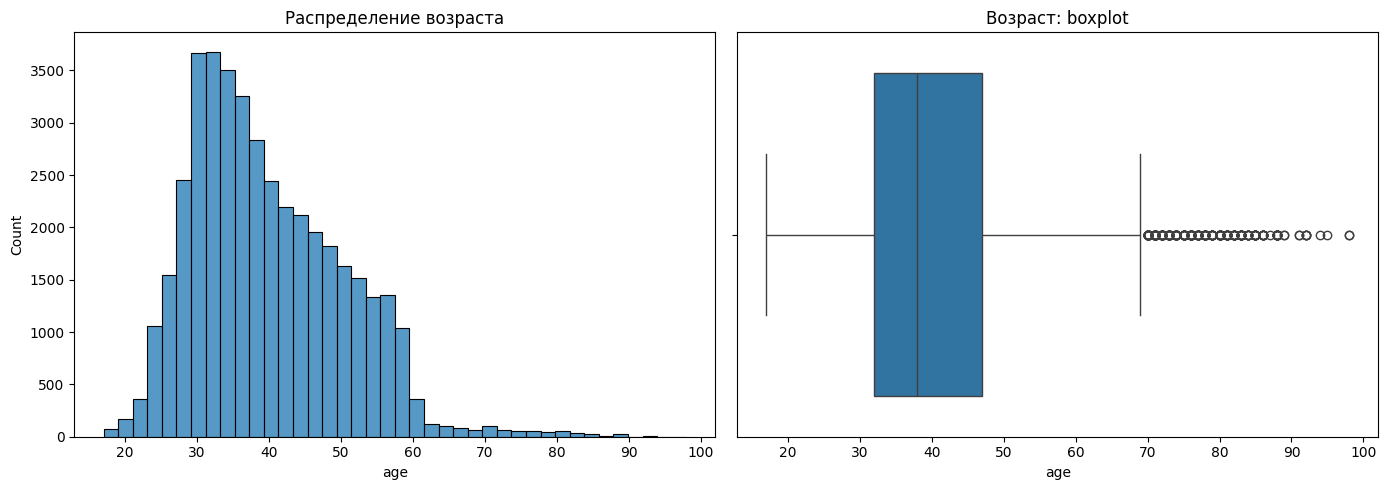

In [80]:
# 1. Создаем сетку: 1 строка, 2 столбца. Задаем общий размер картинки (ширина, высота)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# 2. Строим гистограмму на первом графике (ax=axes[0])
sns.histplot(df['age'], bins=40, ax=axes[0])
axes[0].set_title('Распределение возраста')
# 3. Строим boxplot на втором графике (ax=axes[1])
sns.boxplot(x=df['age'], ax=axes[1])
axes[1].set_title('Возраст: boxplot')

# 4. Автоматически выравниваем отступы, чтобы подписи не накладывались
plt.tight_layout()

# 5. Показываем итоговый результат
plt.show()

**Наблюдения.** Возраст от 17 до 98 лет, среднее 40, медиана 38. Основная масса клиентов 30–50 лет, справа умеренный хвост (асимметрия 0.78). Верхняя граница по правилу Тьюки — 69.5 года, за ней 1.1% клиентов.

**Решение.** Возраст 70–98 лет реалистичен: среди клиентов есть пенсионеры (`job = retired`). Это не ошибки данных, а реальные значения, поэтому **оставляем их**. Асимметрия умеренная, преобразование не требуется.

### 3.3 Сводная статистика по числовым признакам

Чтобы не смотреть на каждый признак вслепую, сначала посчитаем для всех числовых признаков:
- **среднее и медиану**: если среднее заметно больше медианы, есть длинный правый хвост;
- **коэффициент асимметрии** (skewness): около 0 — симметрично, больше 1 по модулю — сильная асимметрия;
- **долю выбросов** по правилу Тьюки.

In [81]:
q1 = df[num_cols].quantile(0.25)
q3 = df[num_cols].quantile(0.75)
iqr = q3 - q1
is_outlier = (df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)
stats = pd.DataFrame({
    'среднее': df[num_cols].mean(),
    'медиана': df[num_cols].median(),
    'асимметрия': df[num_cols].skew(),
    'выбросы_%': is_outlier.mean() * 100,
}).round(2)
stats

,среднее,медиана,асимметрия,выбросы_%
age,40.02,38.00,0.78,1.14
duration,258.29,180.00,3.26,7.19
campaign,2.57,2.00,4.76,5.84
pdays,962.48,999.00,-4.92,3.68
previous,0.17,0.00,3.83,13.66
emp.var.rate,0.08,1.10,-0.72,0.00
cons.price.idx,93.58,93.75,-0.23,0.00
cons.conf.idx,-40.50,-41.80,0.30,1.09
euribor3m,3.62,4.86,-0.71,0.00
nr.employed,5167.04,5191.00,-1.04,0.00


**Сильная асимметрия** у признаков клиента и звонка: `campaign` (4.76), `previous` (3.83), `duration` (3.26). У `duration` среднее 258 с при медиане 180 с: длинные звонки тянут среднее вверх.

**`pdays` (−4.92)** — асимметрия искусственная: 96% значений равны служебному 999, а настоящие значения выглядят как хвост влево.

**Правило Тьюки не всегда применимо.** У `pdays` и `previous` квартили $Q_1 = Q_3$ (999 и 0 соответственно), поэтому $IQR = 0$, и **любое** отличное значение считается выбросом: 13.7% «выбросов» у `previous` — это просто все клиенты, с которыми раньше был контакт. Для таких признаков правило Тьюки неинформативно, решение принимаем по смыслу.

**Экономические признаки** почти симметричны и выбросов по Тьюки не имеют (кроме 1% у `cons.conf.idx`).

### 3.4 Скошенные признаки

Смотрим на графики признаков с сильной асимметрией, чтобы понять форму хвоста и решить, реальные ли экстремальные значения. Для повторяющегося кода используем функцию.

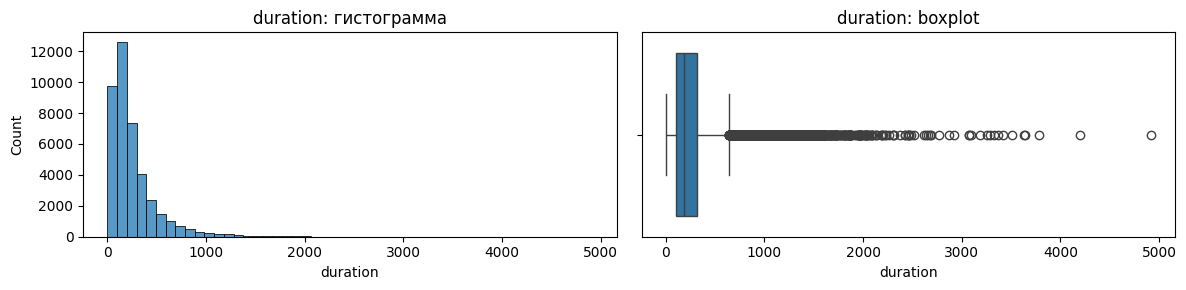

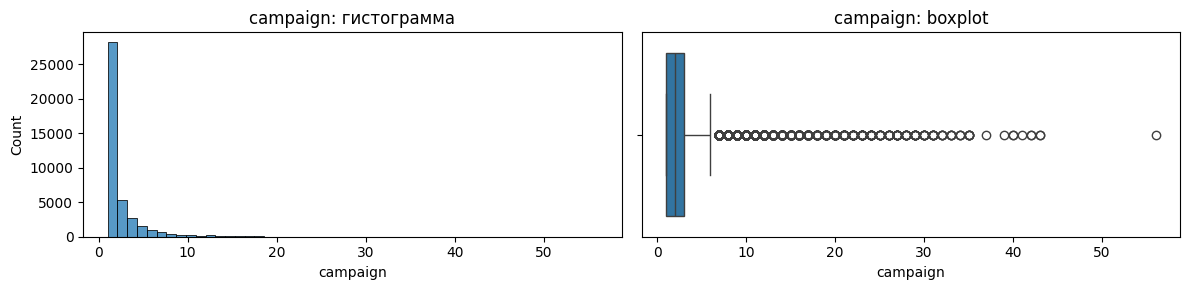

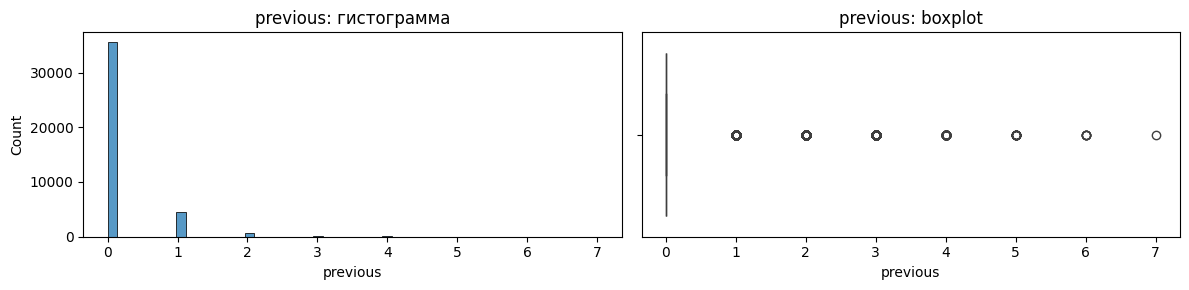

In [82]:
def plot_numeric(col, data=None):
    """Гистограмма и boxplot признака рядом."""
    data = df[col] if data is None else data
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    sns.histplot(data, bins=50, ax=axes[0])
    axes[0].set_title(f'{col}: гистограмма')
    sns.boxplot(x=data, ax=axes[1])
    axes[1].set_title(f'{col}: boxplot')
    plt.tight_layout()
    plt.show()

for col in ['duration', 'campaign', 'previous']:
    plot_numeric(col)

- **`duration`**: медиана 180 с (3 минуты), максимум 4918 с (≈ 82 минуты). Длинные разговоры реальны: заинтересованный клиент задаёт вопросы. 4 звонка с длительностью 0 — клиент не ответил. Ошибок нет. Признак не будем использовать так как это утечка данных.
- **`campaign`**: 81% клиентам звонили не больше 3 раз, но есть значения до 56 звонков. Большое число повторных звонков в одной кампании правдоподобно (банк настойчиво дозванивается), поэтому это реальные значения.
- **`previous`**: у 86% клиентов 0 предыдущих контактов, максимум 7. Распределение — пик на нуле с коротким хвостом.

In [83]:
# Проверяем числа, на которые опираются выводы
print('Доля клиентов, которым звонили не больше 3 раз:', round((df['campaign'] <= 3).mean(), 3))
print('Доля клиентов без предыдущих контактов:', round((df['previous'] == 0).mean(), 3))
print(df['previous'].value_counts().sort_index())

Доля клиентов, которым звонили не больше 3 раз: 0.815
Доля клиентов без предыдущих контактов: 0.863
previous
0    35563
1     4561
2      754
3      216
4       70
5       18
6        5
7        1
Name: count, dtype: int64


### 3.5 pdays без служебного значения



Значение 999 занимает 96% столбца `pdays`, поэтому на общем графике реальные значения не видны. Строим распределение только по клиентам, у которых записано число дней с прошлого контакта.

Клиентов с записанным числом дней: 1515


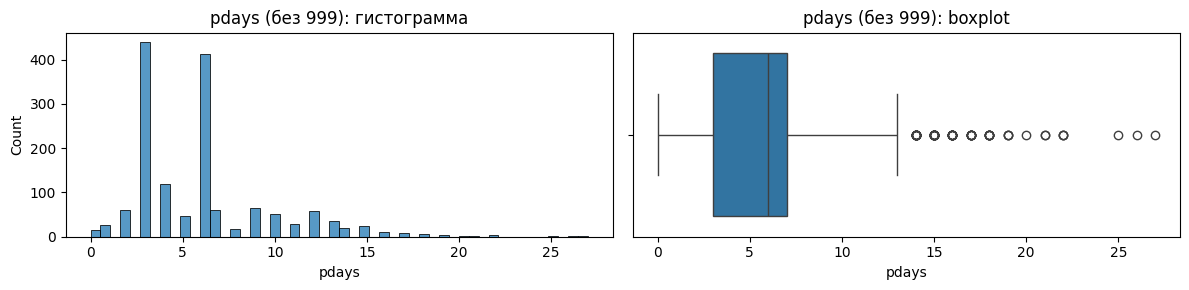

In [84]:
real_pdays = df.loc[df['pdays'] != 999, 'pdays']   # только настоящие значения
print('Клиентов с записанным числом дней:', len(real_pdays))
plot_numeric('pdays (без 999)', real_pdays)

In [85]:
pd.crosstab(
    pd.Categorical((df['previous'] > 0).map({False: 'Раньше не звонили (previous = 0)', True: 'Раньше звонили (previous > 0)'}),
                   categories=['Раньше не звонили (previous = 0)', 'Раньше звонили (previous > 0)'], ordered=True),
    pd.Categorical((df['pdays'] != 999).map({False: 'Дни не записаны (pdays = 999)', True: 'Дни записаны'}),
                   categories=['Дни не записаны (pdays = 999)', 'Дни записаны'], ordered=True),
    rownames=[''],
    colnames=['']
)


,Дни не записаны (pdays = 999),Дни записаны
,,
Раньше не звонили (previous = 0),35563,0
Раньше звонили (previous > 0),4110,1515


Число дней записано у 1515 клиентов (3.7%). Для них интервал от 0 до 27 дней, медиана 6 дней — значения правдоподобные. Проблема признака не в выбросах, а в служебном значении 999, которое нельзя трактовать как число дней.

**Несогласованность в данных.** По описанию датасета `pdays = 999` означает «раньше не звонили». Но таблица сопряжённости показывает, что у 4 110 клиентов с `pdays = 999` прошлые контакты были (`previous > 0`). Значит, 999 означает скорее «нет данных о числе дней». Фактически без прошлых контактов 86% клиентов, а не 96%.

**Решение.** Признак «был ли контакт раньше» будем строить по `previous > 0`, а не по `pdays`: `previous` надёжнее отражает факт прошлого контакта.

### 3.6 Логарифмическое преобразование

Для линейных моделей сильная асимметрия нежелательна: экстремальные значения непропорционально влияют на обучение. Стандартное решение — преобразование $\log(1 + x)$: оно сохраняет порядок значений, но сжимает правый хвост. Единица добавляется, потому что у признаков есть нули, а $\log 0$ не определён. Проверим, как меняется асимметрия.

In [86]:
skewed = ['duration', 'campaign', 'previous']
pd.DataFrame({
    'до': df[skewed].skew(),
    'после log(1+x)': np.log1p(df[skewed]).skew(),
}).round(2)

,до,после log(1+x)
duration,3.26,-0.42
campaign,4.76,1.35
previous,3.83,2.59


| Признак | Асимметрия до | После $\log$ | Вывод |
|---|---|---|---|
| `duration` | 3.26 | −0.42 | логарифм почти полностью устраняет асимметрию |
| `campaign` | 4.76 | 1.35 | асимметрия заметно уменьшилась — **применяем логарифм в пайплайне** |
| `previous` | 3.83 | 2.59 | логарифм не помогает: 86% значений равны нулю, а пик в одной точке преобразованием не «растянуть» |

**Решение.** `campaign` — логарифмировать. Для `previous` важнее факт «был ли контакт», чем точное число, — это учтём в новых признаках.

### 3.7 Экономические признаки

Эти признаки описывают не клиента, а состояние экономики в момент звонка, поэтому одинаковы для всех, кому звонили в один период. Ожидаем небольшое число отдельных значений вместо плавного распределения.

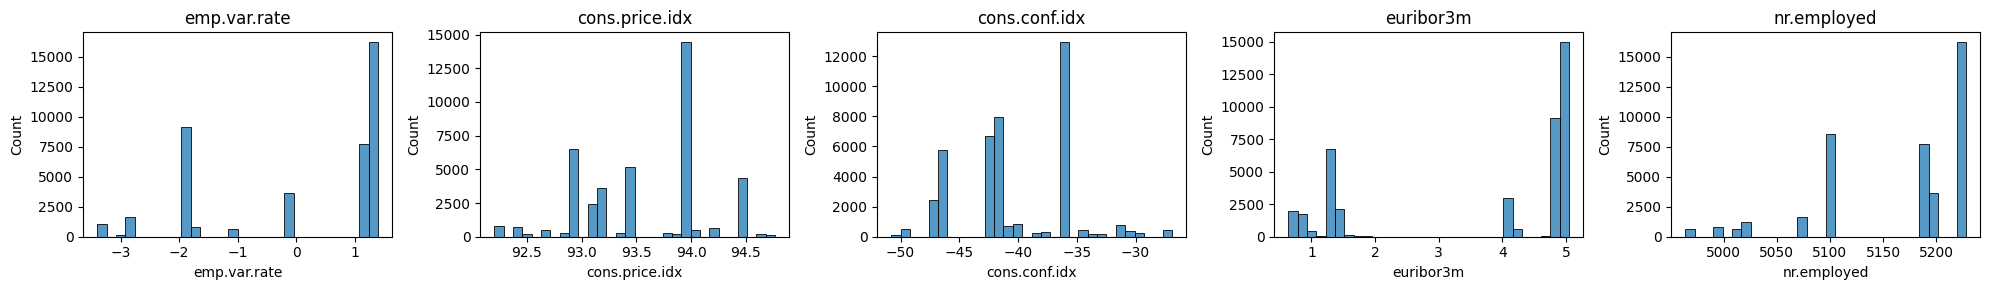

In [87]:
econ_cols = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

fig, axes = plt.subplots(1, 5, figsize=(20, 3))
for ax, col in zip(axes, econ_cols):      # zip: берём пары (график, признак)
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Все пять признаков **дискретные**: от 10 (`emp.var.rate`) до 26 (`cons.price.idx`) уникальных значений, только у `euribor3m` их 316. Гистограммы состоят из отдельных столбиков.

У `euribor3m` **два режима**: значения группируются около 0.6–1.5% и около 4–5%. Это отражает два разных периода экономики: высокие ставки до кризиса и резкое снижение после. По той же причине у `emp.var.rate` среднее (0.08) сильно отличается от медианы (1.1).

Выбросов нет: все значения — реальные макроэкономические показатели. Преобразования не нужны. Признаки, вероятно, сильно связаны между собой — проверим в матрице корреляций.

**`nr.employed`** (число занятых, тыс. человек) принимает всего 11 значений, от 4963.6 до 5228.1. Асимметрия −1.04 вызвана не выбросами, а тем, что большинство звонков пришлось на периоды высокой занятости: 39% всех звонков — при значении 5228.1. Периоды с низкой занятостью (4963–5100) — более поздние, кризисные, и в них звонили реже. Все значения — реальные показатели экономики, выбросов нет.

### 3.8 Категориальные признаки

Для каждого категориального признака строим частоты категорий, отсортированные по убыванию. Ищем доминирующие и редкие категории. Пропуски (`NaN`) на графиках не отображаются, их доли приведены в разделе «Обзор».

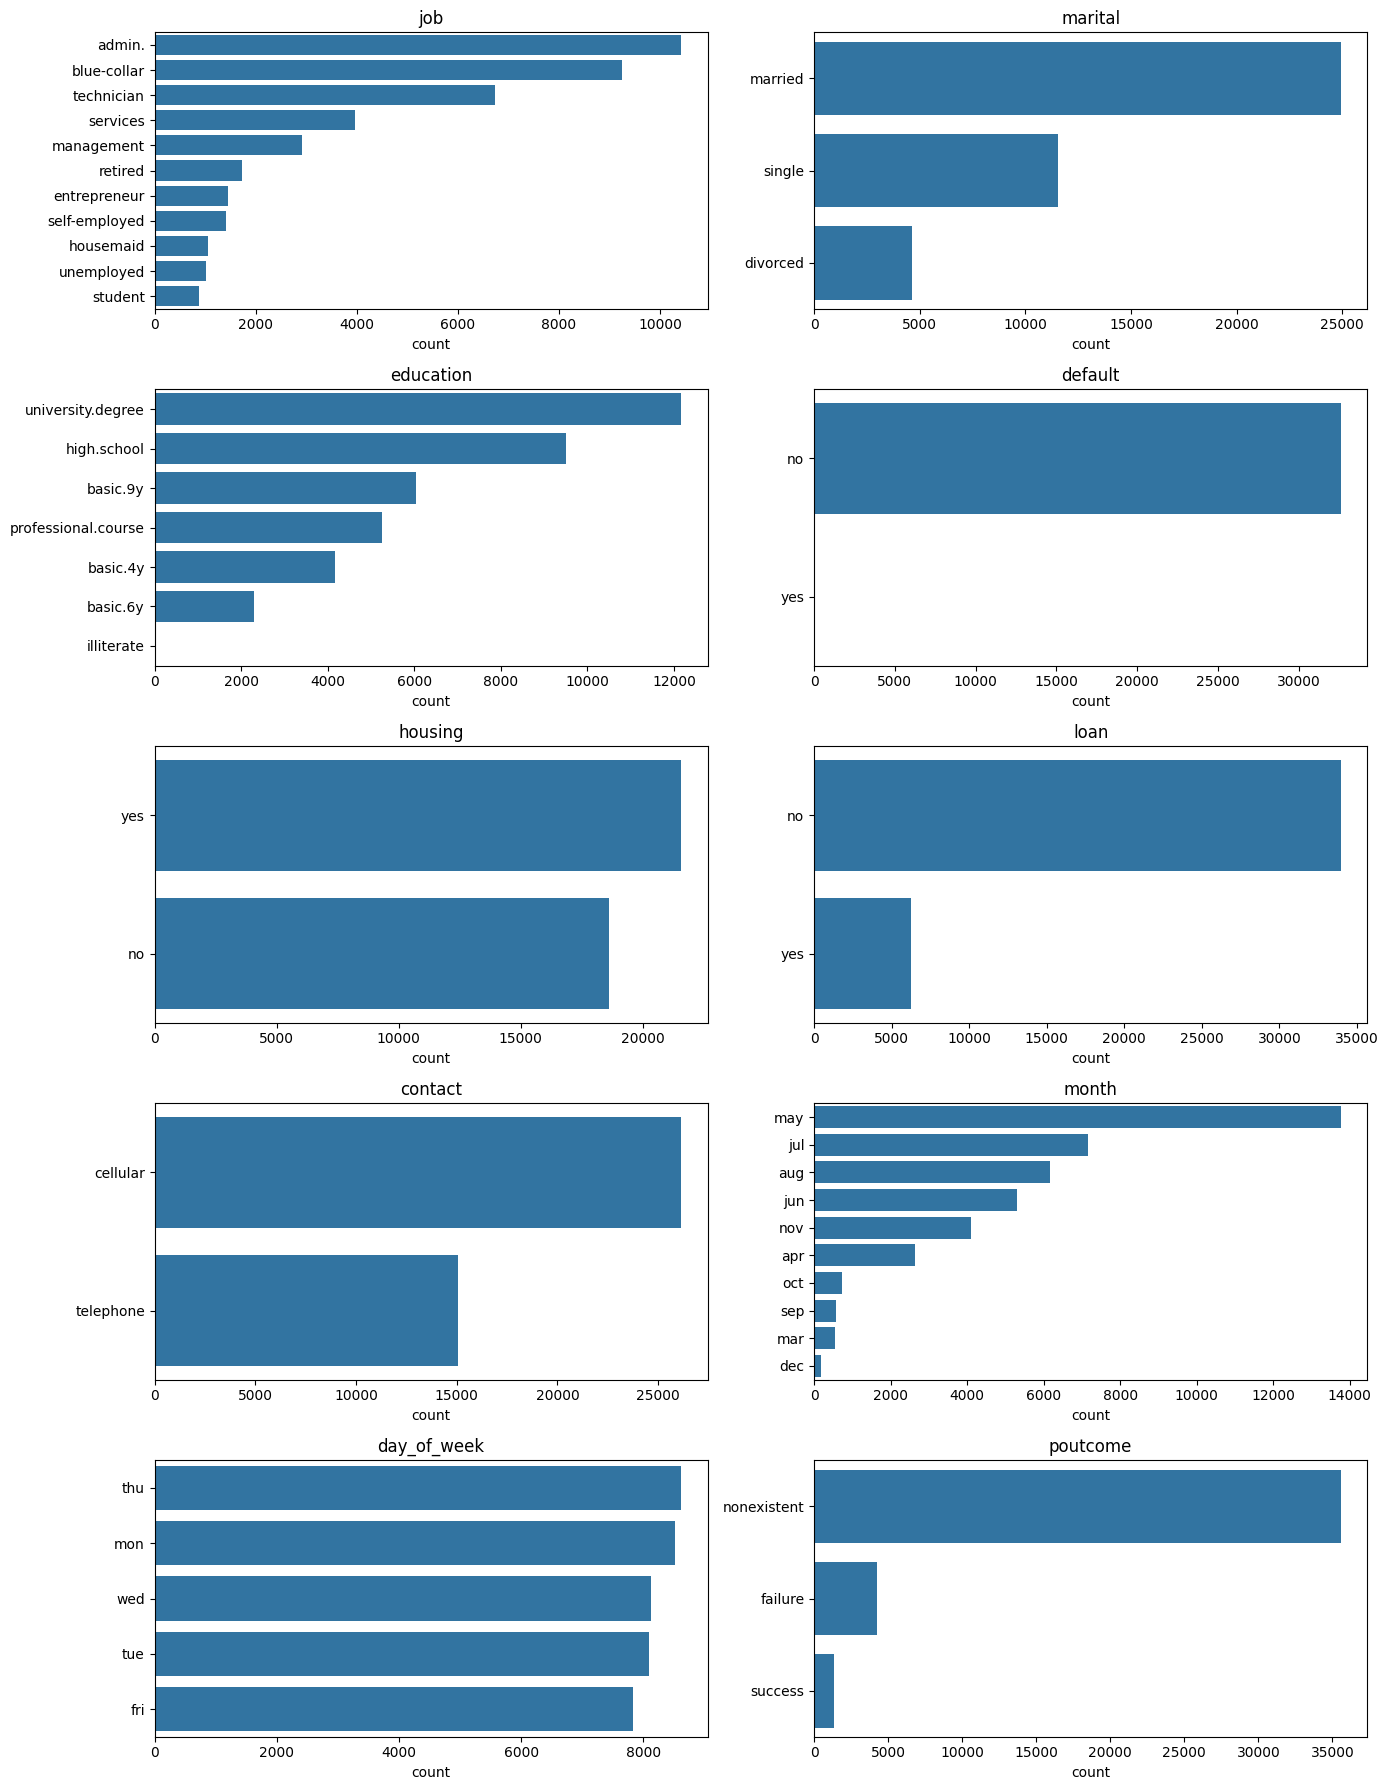

In [88]:
fig, axes = plt.subplots(5, 2, figsize=(14, 18))
for ax, col in zip(axes.flat, cat_cols):    # axes.flat: сетка 5×2 как один список
    order = df[col].value_counts().index    # категории от частых к редким
    sns.countplot(y=df[col], order=order, ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

- **`job`**: три самые частые профессии — admin. (25%), blue-collar (22%), technician (16%); остальные от 2% до 10%.
- **`marital`**: преобладают женатые (61%).
- **`education`**: чаще всего высшее образование (30%) и среднее (23%); категория `illiterate` почти пуста.
- **`default`**: 79% — `no`, 21% — пропуск, `yes` всего у 3 клиентов. Признак фактически принимает два значения: «нет» и «неизвестно».
- **`housing`**: ипотека примерно у половины клиентов (52%). **`loan`**: потребительский кредит у 15%.
- **`contact`**: 63% звонков на мобильный.
- **`month`**: сильный перекос: 33% звонков в мае, в декабре лишь 0.4%, январь и февраль отсутствуют. Кампании проводились неравномерно по году.
- **`day_of_week`**: звонки распределены почти равномерно (19–21% на каждый рабочий день).
- **`poutcome`**: у 86% клиентов прошлой кампании не было; успешный исход (`success`) — лишь у 3.3%. Категория малочисленная, но потенциально очень информативная — проверим её связь с целевой переменной.

### 3.9 Редкие категории

Выведем категории, в которых меньше 1% объектов. По таким категориям нельзя надёжно оценить связь с целевой переменной, и модель может на них переобучиться.

In [89]:
for col in cat_cols:
    share = df[col].value_counts(normalize=True) * 100
    rare = share[share < 1]               # категории с долей меньше 1%
    if len(rare) > 0:
        print(col, rare.round(2).to_dict())

education {'illiterate': 0.05}
default {'yes': 0.01}
month {'dec': 0.44}


| Признак | Редкая категория | Объектов | Решение |
|---|---|---|---|
| `default` | `yes` | 3 | статистически бесполезна; в кодировщике `handle_unknown='ignore'`, чтобы категория, не попавшая в train, не вызывала ошибку |
| `education` | `illiterate` | 18 | объединить с ближайшей по смыслу категорией `basic.4y` |
| `month` | `dec` | 182 | оставить: 182 объекта достаточно для оценки, а месяц будет закодирован циклически |

Прежде чем объединять редкие категории, проверим в двумерном анализе, не отличаются ли они резко по доле `yes`: редкая категория может оказаться самой информативной.

### 3.10 Выводы по одномерному анализу

**Скошенность.** Сильная правосторонняя асимметрия у `campaign`, `previous`, `duration`. Для `campaign` применим $\log(1+x)$ (асимметрия снижается с 4.76 до 1.35). `duration` в модель не войдёт из-за утечки. У `previous` 86% нулей, поэтому информативнее бинарный признак «был ли контакт».

**Выбросы.** Экстремальные значения `age` (до 98 лет), `campaign` (до 56 звонков), `duration` (до 82 минут) правдоподобны и не являются ошибками данных — оставляем. Правило Тьюки неприменимо к `pdays` и `previous`, где $IQR = 0$. Главная проблема `pdays` — служебное значение 999 у 96% объектов.

**Редкие категории.** `default = yes` (3 объекта), `education = illiterate` (18), `month = dec` (182). Признак `default` фактически бинарный: «нет» или «неизвестно».

**Особенности.** Экономические признаки дискретны и отражают разные периоды; у `euribor3m` два режима (низкие и высокие ставки). Звонки распределены по месяцам неравномерно (33% в мае).

**Решения для пайплайна:**
- логарифм для `campaign`;
- бинарный признак «был ли контакт раньше» вместо `pdays`;
- `handle_unknown='ignore'` в кодировании категорий, объединение `illiterate` с `basic.4y`;
- `duration` исключаем.

## 4. Двумерный анализ

**Цель.** Изучить связь признаков с целевой переменной: какие признаки помогают отличить клиентов, открывших вклад, от остальных. Именно эти связи будет использовать модель.

### 4.1 Целевая переменная в числовом виде

Чтобы считать доли, переводим `y` в числа: `yes` → 1, `no` → 0.

In [90]:
df['target'] = (df['y'] == 'yes').astype(int)
base_rate = df['target'].mean()
print(f'Доля yes по всем данным: {base_rate:.1%}')

def rate_by(col, data=None):
    """Доля yes (%) и число клиентов в каждой группе признака."""
    data = df[col] if data is None else data
    # Для интервалов из pd.cut/pd.qcut сначала разрешаем новую категорию 'missing'
    if isinstance(data.dtype, pd.CategoricalDtype):
        data = data.cat.add_categories('missing')
    data = data.fillna('missing')
    table = (df.groupby(data, observed=True)['target']
               .agg(['mean', 'size'])
               .rename(columns={'mean': 'доля_yes_%', 'size': 'клиентов'})
               .sort_values('доля_yes_%', ascending=False))
    table['доля_yes_%'] = (table['доля_yes_%'] * 100).round(1)
    return table

def plot_rate(table, title, ax):
    """Столбики с долей yes по группам; красная линия — средняя доля."""
    sns.barplot(x=table['доля_yes_%'], y=table.index.astype(str), ax=ax, color='steelblue')
    ax.axvline(base_rate * 100, color='red', linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('доля yes, %')
    ax.set_ylabel('')

Доля yes по всем данным: 11.3%


### 4.2 Категориальные признаки

Для каждого категориального признака строим долю `yes` по категориям. Пропуски выделены в отдельную группу `missing`, чтобы проверить, связан ли сам факт пропуска с целевой переменной. Красная линия — средняя доля (11.3%).

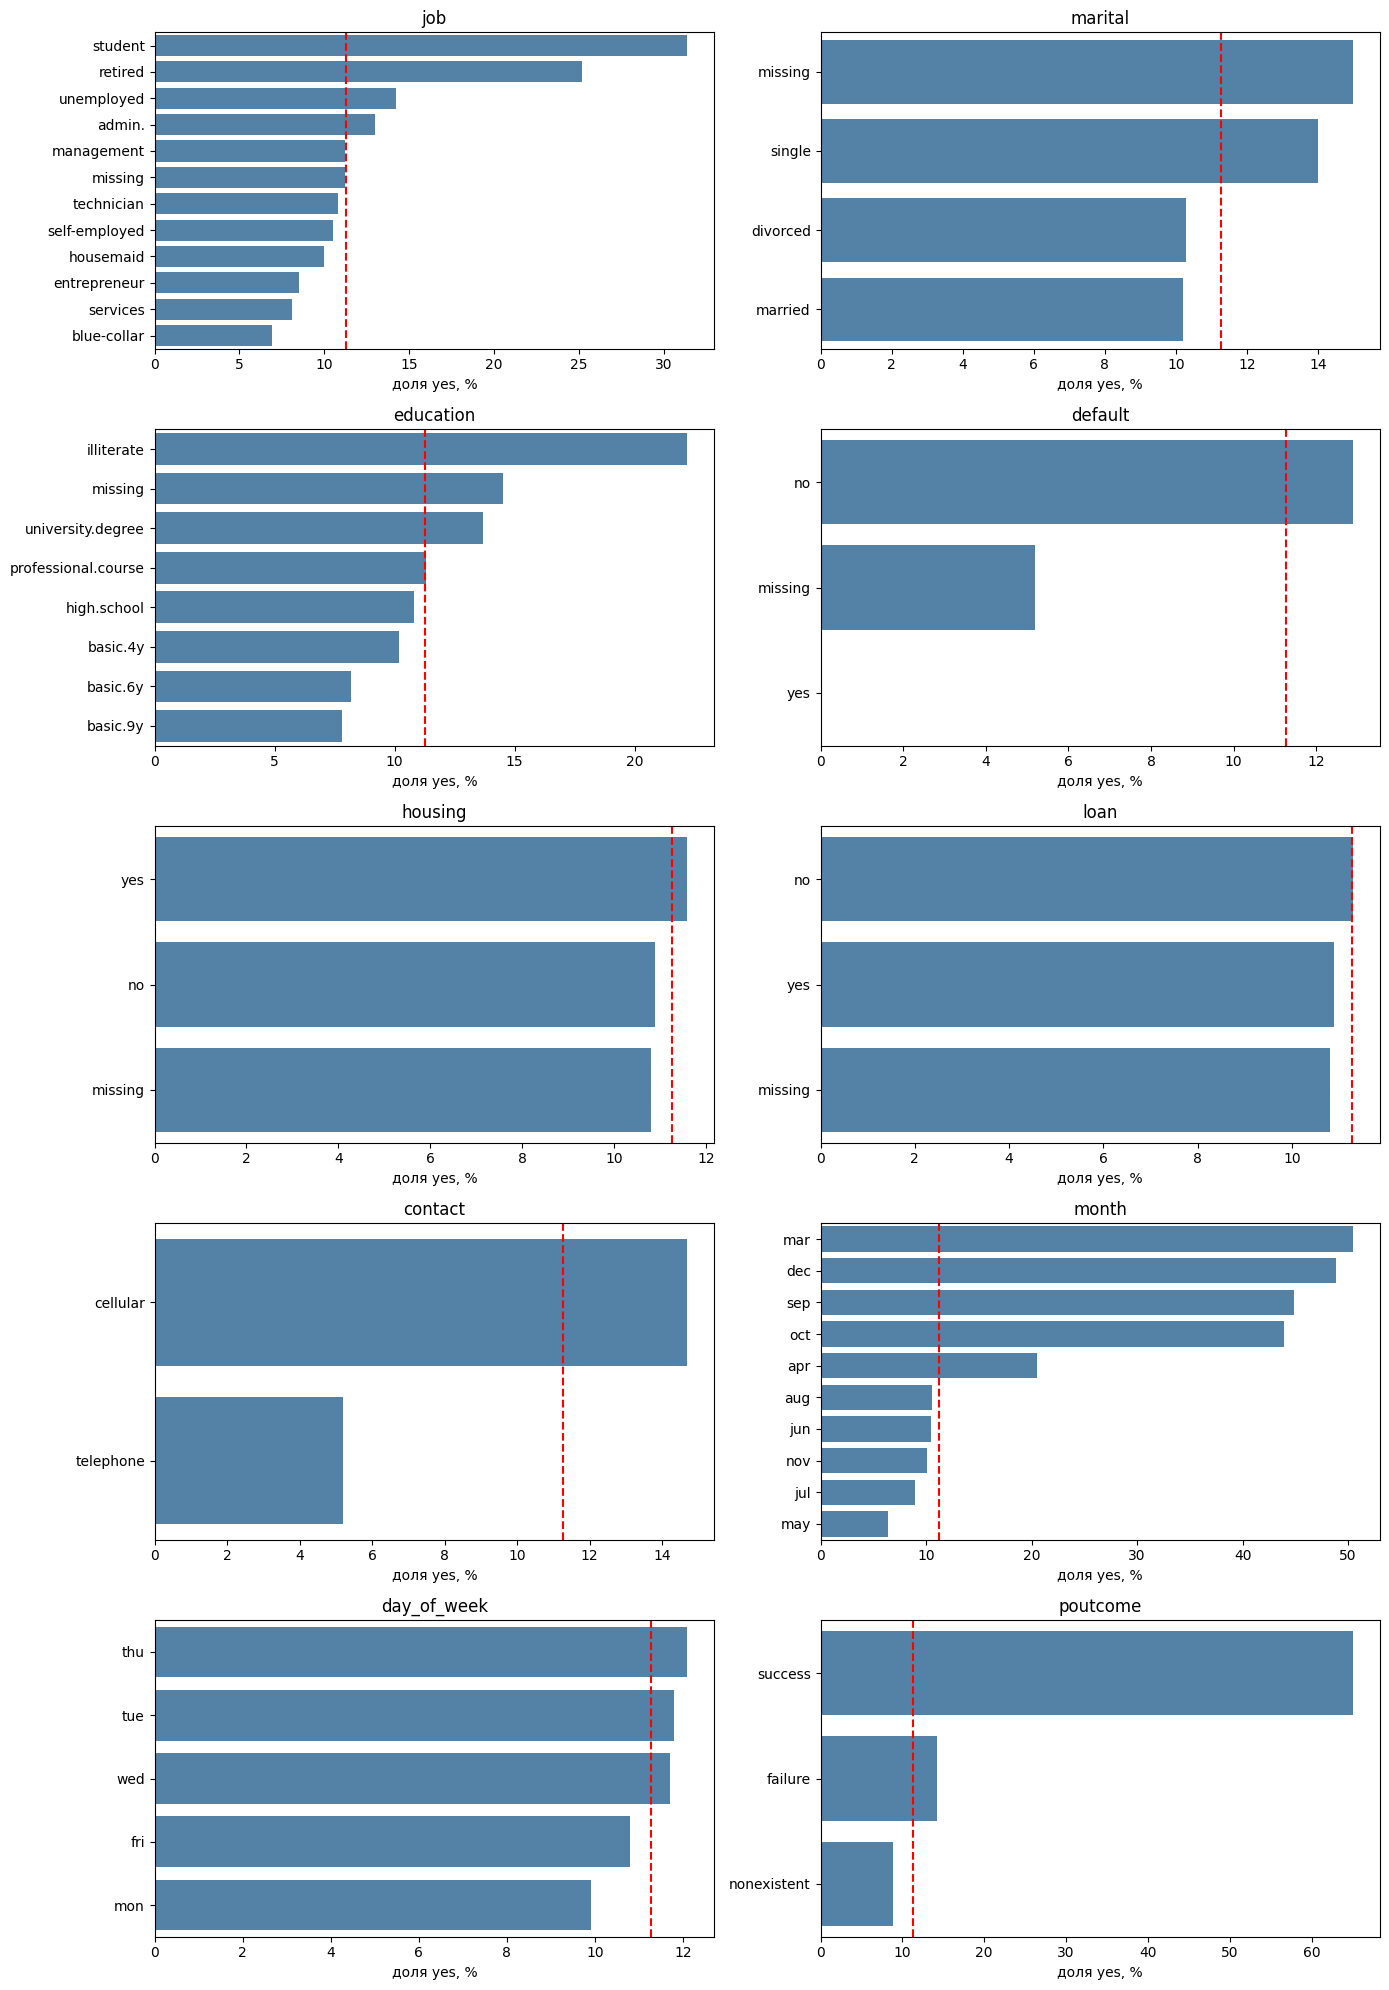

In [91]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
for ax, col in zip(axes.flat, cat_cols):
    plot_rate(rate_by(col), col, ax)
plt.tight_layout()
plt.show()

In [92]:
for col in ['poutcome', 'contact', 'default', 'month']:
    print(rate_by(col), '\n')

             доля_yes_%  клиентов
poutcome                         
success            65.1      1373
failure            14.2      4252
nonexistent         8.8     35563 

           доля_yes_%  клиентов
contact                        
cellular         14.7     26144
telephone         5.2     15044 

         доля_yes_%  клиентов
default                      
no             12.9     32588
missing         5.2      8597
yes             0.0         3 

       доля_yes_%  клиентов
month                      
mar          50.5       546
dec          48.9       182
sep          44.9       570
oct          43.9       718
apr          20.5      2632
aug          10.6      6178
jun          10.5      5318
nov          10.1      4101
jul           9.0      7174
may           6.4     13769 



**Сильные связи:**
- **`poutcome`** — самый сильный категориальный признак. Если прошлая кампания закончилась успехом, вклад открывают **65.1%** клиентов, это в 6 раз выше среднего. При неудаче — 14.2%, если прошлой кампании не было — 8.8%.
- **`month`** — в марте, сентябре, октябре и декабре доля `yes` 44–51%, тогда как в мае, самом загруженном месяце (33% всех звонков), всего 6.4%. Месяцы с высокой долей — это месяцы с малым числом звонков.
- **`contact`** — при звонке на мобильный доля `yes` 14.7%, на стационарный — 5.2%, почти в 3 раза ниже.
- **`job`** — выделяются студенты (31.4%) и пенсионеры (25.2%); ниже всего у рабочих (blue-collar, 6.9%).


**Пропуск как информация:**
- **`default`** — у клиентов с пропуском доля `yes` 5.2%, у клиентов с `default = no` — 12.9%. **Сам факт пропуска связан с целевой переменной**: клиенты, не сообщившие о просрочке, реже открывают вклад. Это аргумент в пользу того, чтобы не заполнять пропуск самой частой категорией, а сохранить его как отдельную категорию или флаг (разделы 6 и 11).

**Слабые связи:**
- **`housing`** и **`loan`** — доля `yes` почти одинакова во всех группах (10.8–11.6%). Наличие кредитов почти не влияет на решение.
- **`day_of_week`** — разброс от 9.9% (понедельник) до 12.1% (четверг), связь слабая.

**Редкие категории.** `education = illiterate` (22.2%) и `month = dec` (48.9%) имеют высокую долю `yes`. Но у `illiterate` всего 18 клиентов (4 открыли вклад), и один дополнительный `yes` изменил бы долю на 5.5 процентного пункта — эта оценка ненадёжна, поэтому объединение с `basic.4y` оправдано. Декабрь (182 клиента) оставляем отдельной категорией: оценка надёжнее, а отличие от среднего огромно.

### 4.3 Возраст

Сравниваем долю `yes` в возрастных группах. Разбиение на интервалы позволяет увидеть зависимость любой формы, а не только линейную.

           доля_yes_%  клиентов
age                            
(16, 25]         20.9      1666
(25, 30]         13.6      5717
(30, 40]          9.7     16385
(40, 50]          8.2     10240
(50, 60]         10.7      6270
(60, 100]        45.5       910


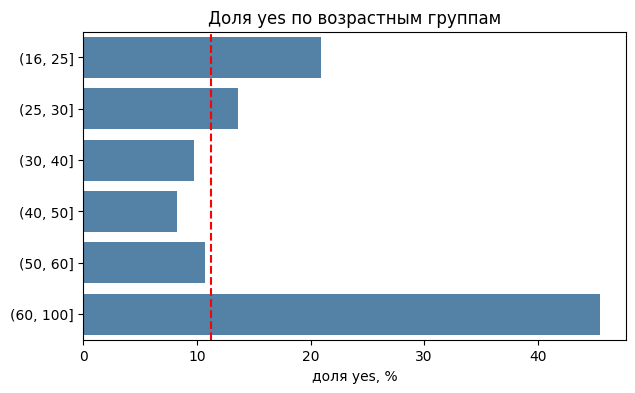

In [93]:
age_groups = pd.cut(df['age'], bins=[16, 25, 30, 40, 50, 60, 100])
age_table = rate_by('age', age_groups).sort_index()
print(age_table)

fig, ax = plt.subplots(figsize=(7, 4))
plot_rate(age_table, 'Доля yes по возрастным группам', ax)
plt.show()

Зависимость **U-образная**: доля `yes` высокая у молодых до 25 лет (20.9%) и особенно у клиентов старше 60 (45.5%), а в середине, 30–50 лет, минимальная (8–10%). Это согласуется с `job`: студенты и пенсионеры открывают вклад чаще всех.

**Следствие для модели.** Медианы возраста у `yes` и `no` почти совпадают (37 и 38 лет), и коэффициент корреляции возраста с целевой переменной близок к нулю. Тем не менее связь есть, просто она нелинейная. Линейная модель, умножающая возраст на один коэффициент, не сможет описать U-образную форму. **Решение:** в разделе 8 создадим признак возрастной группы.

### 4.4 История контактов: `campaign` и `previous`

Проверяем, как доля `yes` зависит от числа звонков в текущей кампании и числа контактов до неё. Значения `campaign` больше 10 объединены в группу «10», чтобы группы не были слишком маленькими.

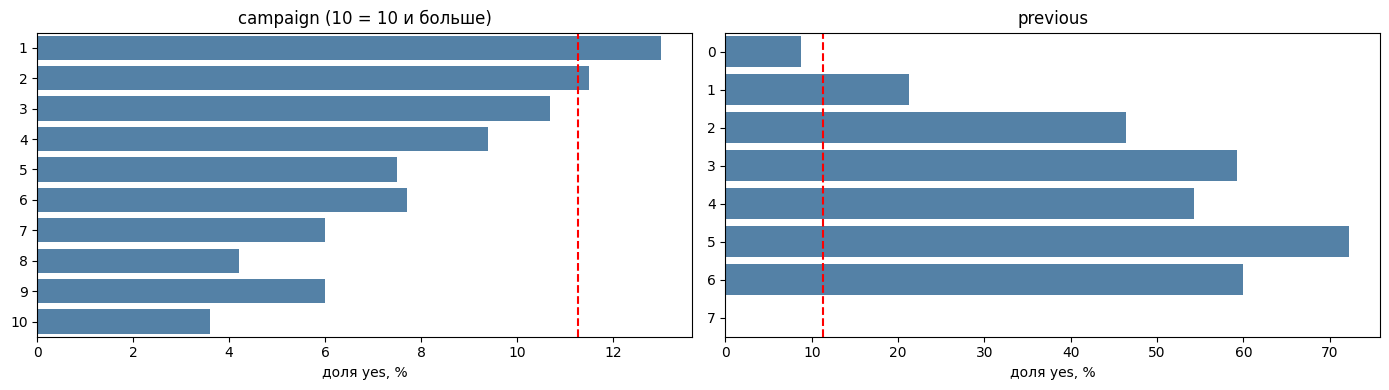

          доля_yes_%  клиентов
previous                      
0                8.8     35563
1               21.2      4561
2               46.4       754
3               59.3       216
4               54.3        70
5               72.2        18
6               60.0         5
7                0.0         1


In [94]:
campaign_capped = df['campaign'].clip(upper=10)   # всё, что больше 10, становится 10

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_rate(rate_by('campaign', campaign_capped).sort_index(), 'campaign (10 = 10 и больше)', axes[0])
plot_rate(rate_by('previous').sort_index(), 'previous', axes[1])
plt.tight_layout()
plt.show()

print(rate_by('previous').sort_index())

**`campaign`.** Чем больше звонков в текущей кампании, тем ниже доля `yes`: 13.0% после первого звонка, 7.5% после пятого, 3.6% после десяти и более. Клиенты, которых удаётся убедить, обычно соглашаются быстро; многократные звонки малоэффективны. Для банка это практический вывод: после 5–6 безуспешных звонков продолжать дозваниваться почти бессмысленно.

**`previous`.** Обратная зависимость: клиенты с прошлыми контактами открывают вклад гораздо чаще. Без прошлых контактов — 8.8%, с одним — 21.2%, с двумя — 46.4%, с тремя — 59.3%. Значения 5–7 встречаются у единиц клиентов, и доли по ним ненадёжны (например, при `previous = 7` всего 1 клиент). Это подтверждает решение создать бинарный признак «был ли контакт раньше» (раздел 8).

### 4.5 Экономический контекст

Проверяем, зависит ли успех звонка от состояния экономики. Для `euribor3m` используем интервалы ставки, для `nr.employed` — его 11 значений.

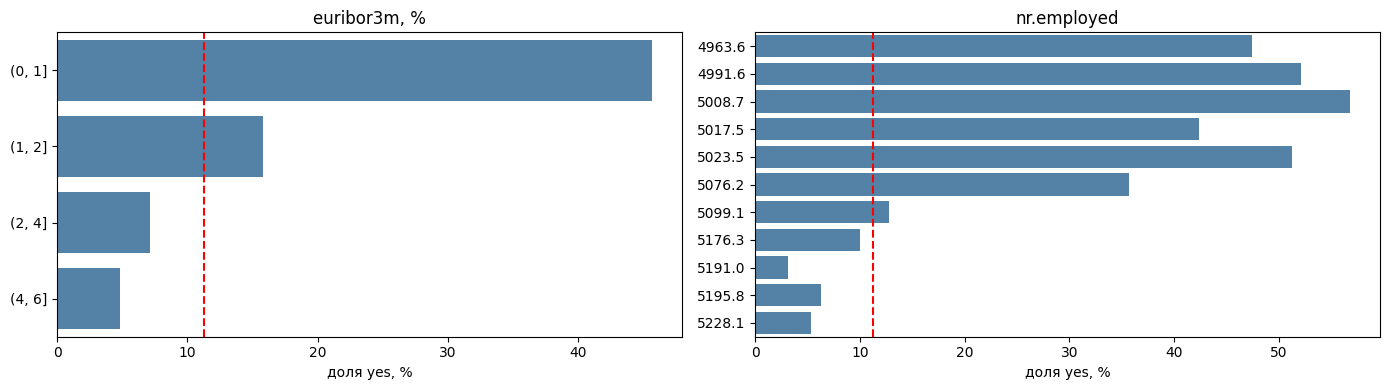

           доля_yes_%  клиентов
euribor3m                      
(0, 1]           45.7      3908
(1, 2]           15.8      9590
(2, 4]            7.1        14
(4, 6]            4.8     27676


In [95]:
euribor_groups = pd.cut(df['euribor3m'], bins=[0, 1, 2, 4, 6])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_rate(rate_by('euribor3m', euribor_groups).sort_index(), 'euribor3m, %', axes[0])
plot_rate(rate_by('nr.employed').sort_index(), 'nr.employed', axes[1])
plt.tight_layout()
plt.show()

print(rate_by('euribor3m', euribor_groups).sort_index())

Экономические признаки связаны с целевой переменной **сильнее всех признаков клиента**, кроме `poutcome`:
- при ставке Euribor до 1% вклад открывают **45.7%** клиентов, при ставке выше 4% — только **4.8%**;
- при низкой занятости (`nr.employed` < 5100) доля `yes` 36–57%, при высокой (5191–5228) — 3–6%.

**Как это интерпретировать. Возможны два объяснения: в кризисный период люди охотнее сберегали деньги на надёжных вкладах; или в этот период банк звонил меньше и более целенаправленно. Второе подтверждается тем, что периоды с высокой долей `yes` — это периоды с малым числом звонков (как и месяцы март, сентябрь, октябрь, декабрь в разделе 4.2). Скорее всего, действуют оба фактора.

**Важно для модели.** Эти признаки описывают период, а не клиента. Модель, сильно опирающаяся на них, по сути учится определять «удачный период», и её качество может упасть, если экономическая ситуация изменится. Это нужно учесть при разбиении данных и в анализе утечки.


  *Уточнение:* 85% звонков на стационарные телефоны пришлись на май и июнь — период высоких ставок, когда доля `yes` низкая у всех. Внутри одного периода разница меньше: при Euribor > 2% — 5.7% (мобильный) против 3.9% (стационарный), при Euribor ≤ 2% — 25.1% против 18.6%. Значит, часть различия объясняется не типом связи, а периодом звонка (скрытый третий фактор).

### 4.6 Длительность звонка и утечка

Проверяем связь `duration` с целевой переменной, чтобы подтвердить, что признак содержит информацию об исходе звонка. Разбиваем длительность на 5 равных по числу клиентов групп (квинтили).

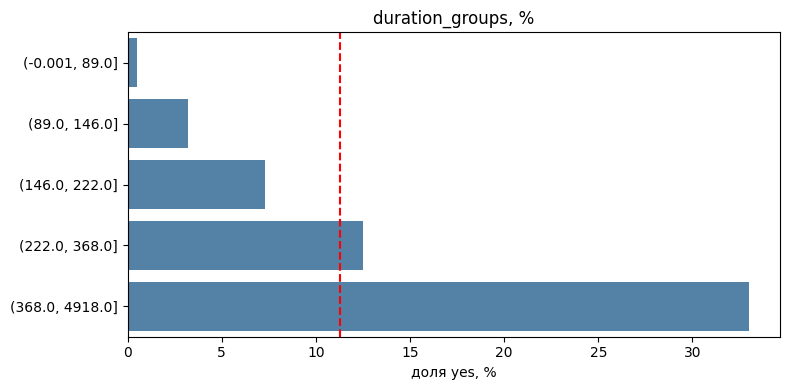

                 доля_yes_%  клиентов
duration                             
(-0.001, 89.0]          0.5      8388
(89.0, 146.0]           3.2      8139
(146.0, 222.0]          7.3      8274
(222.0, 368.0]         12.5      8165
(368.0, 4918.0]        33.0      8222


In [96]:
duration_groups = pd.qcut(df['duration'], q=5)   # 5 групп по ~8200 клиентов
fig, ax = plt.subplots(figsize=(8, 4))
plot_rate(rate_by('duration', duration_groups).sort_index(), 'duration_groups, %', ax)
plt.tight_layout()
plt.show()
print(rate_by('duration', duration_groups).sort_index())

Связь очень сильная: в самой короткой пятой части звонков (до 89 с) доля `yes` **0.5%**, в самой длинной (более 368 с) — **33%**. Из 4 181 звонка короче минуты вклад открыл 1 клиент.

Это подтверждает утечку: длительность определяется исходом разговора (согласившийся клиент обсуждает детали дольше), а известна она только после звонка. Признак выглядел бы одним из самых полезных, но в момент принятия решения «звонить или нет» его не существует. **`duration` исключаем из модели** .

### 4.7 Выводы по двумерному анализу

1. **Прошлый опыт клиента — самый сильный сигнал.** Клиенты с успешной прошлой кампанией (`poutcome = success`) открывают вклад в 65% случаев против 11% в среднем; с ростом числа прошлых контактов (`previous`) доля `yes` растёт с 9% до 46–59%.

2. **Успех кампании сильно зависит от экономического периода.** При низкой ставке Euribor (до 1%) вклад открывают 46% клиентов, при высокой (выше 4%) — менее 5%. Периоды с высокой долей `yes` совпадают с периодами малого числа звонков, поэтому связь отражает и экономическую ситуацию, и стратегию банка; это не обязательно причинно-следственная связь.

3. **Зависимость от возраста нелинейная (U-образная).** Чаще всего вклад открывают клиенты до 25 и старше 60 лет (21% и 46%), реже всего — клиенты 30–50 лет (8–10%). Совпадает с профессиями: студенты (31%) и пенсионеры (25%) — лидеры. Линейная модель такую зависимость по сырому возрасту не уловит, поэтому нужен признак возрастной группы.

4. **Настойчивость не окупается.** С ростом числа звонков в текущей кампании доля `yes` падает с 13% (1 звонок) до 3.6% (10 и более).

5. **Пропуск информативен.** Клиенты с неизвестным `default` открывают вклад в 2.5 раза реже (5.2% против 12.9%), поэтому пропуск стоит сохранить как отдельную категорию или флаг.

6. **Слабые признаки:** `housing`, `loan`, `day_of_week` почти не влияют на долю `yes`.

7. **`duration` подтверждена как утечка:** доля `yes` растёт с 0.5% до 33% с длительностью звонка, но длительность известна только после звонка.
8. **Не все связи прямые.** Различие по `contact` (15% против 5%) во многом объясняется тем, что звонки на стационарные телефоны сосредоточены в неудачном периоде (май–июнь). Внутри одного периода разница в 1.3–1.5 раза, а не в 2.8. Поэтому связи с целевой переменной нужно проверять на скрытые факторы.

## 5. Матрица корреляций
1. **мультиколлинеарность.**

2. **Какие числовые признаки линейно связаны с целевой переменной.**

### 5.1 Тепловая карта корреляций

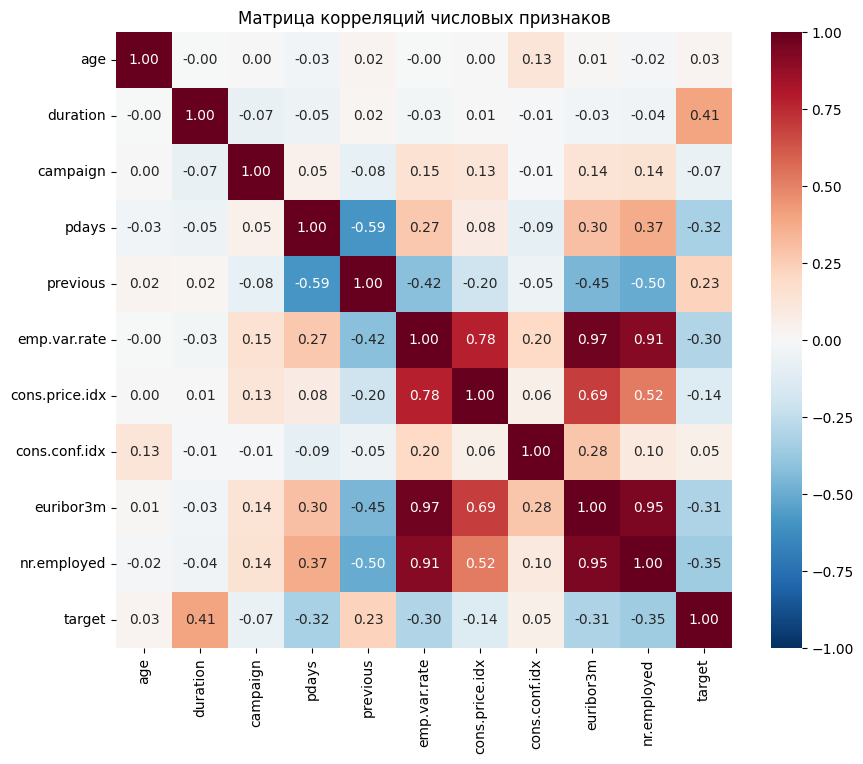

In [97]:
corr= df[num_cols +["target"]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr,  annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Матрица корреляций числовых признаков')
plt.show()

**Блок экономических признаков — сильная мультиколлинеарность.**

| Пара | $r$ |
|---|---|
| `emp.var.rate` — `euribor3m` | 0.97 |
| `euribor3m` — `nr.employed` | 0.95 |
| `emp.var.rate` — `nr.employed` | 0.91 |
| `emp.var.rate` — `cons.price.idx` | 0.78 |

Три признака (`emp.var.rate`, `euribor3m`, `nr.employed`) почти дублируют друг друга: все они отражают одно состояние экономики в момент звонка. Это подтверждает вывод раздела 3: признаки описывают период, а не клиента. `cons.conf.idx` связан с остальными слабо (до 0.28) и несёт отдельную информацию.

**`pdays` и `previous` ($r = -0.59$)** связаны через служебное значение: у клиентов без прошлых контактов `previous = 0` и `pdays = 999` одновременно. Связь искусственная, она создана кодировкой, а не реальной зависимостью.

**`previous` и экономика ($r$ от −0.42 до −0.50).** Повторные клиенты чаще встречаются в периоды низких ставок и занятости. Значит, часть связи `previous` с целевой переменной может объясняться периодом звонка (тот же скрытый фактор, что у `contact` в разделе 4).

**`age`, `campaign`, `cons.conf.idx`** почти не коррелируют с остальными признаками ($\lvert r \rvert \le 0.15$) и несут независимую информацию.

### 5.2 Корреляция с целевой переменной

Упорядочим признаки по силе линейной связи с `target`. Сортируем по модулю, так как сильная отрицательная связь так же информативна, как положительная.

In [98]:
corr['target'].drop('target').sort_values(key=abs, ascending=False)

,target
duration,0.405274
nr.employed,-0.354678
pdays,-0.324914
euribor3m,-0.307771
emp.var.rate,-0.298334
previous,0.230181
cons.price.idx,-0.136211
campaign,-0.066357
cons.conf.idx,0.054878
age,0.030399


| Признак | $r$ с `target` | Интерпретация |
|---|---|---|
| `duration` | 0.41 | самая сильная связь — но это утечка (раздел 4.6), в модель не берём |
| `nr.employed` | −0.35 | при низкой занятости клиенты соглашаются чаще |
| `pdays` | −0.32 | связь создана служебным значением 999 (см. 5.3) |
| `euribor3m` | −0.31 | при низких ставках соглашаются чаще |
| `emp.var.rate` | −0.30 | то же, признак дублирует `euribor3m` |
| `previous` | 0.23 | больше прошлых контактов — выше доля `yes` |
| `cons.price.idx` | −0.14 | слабая связь |
| `campaign` | −0.07 | слабая линейная связь, хотя в разделе 4.4 доля `yes` монотонно падает с числом звонков |
| `cons.conf.idx` | 0.05 | практически нет |
| `age` | 0.03 | практически нет **линейной** связи, хотя в разделе 4.3 обнаружена сильная U-образная зависимость |

`age` показывает главное ограничение корреляции: нулевая корреляция не означает отсутствия связи, если связь нелинейная.

### 5.3 Проверка: откуда корреляция у `pdays`

Корреляция `pdays` с целевой переменной ($-0.32$) может объясняться не числом дней, а служебным значением 999. Проверим корреляцию только на клиентах с реальными значениями `pdays`.

In [99]:
real_days= df[df['pdays']!=999]
print('Клиентов:', len(real_days))
real_days[['pdays','target']].corr()

Клиентов: 1515


,pdays,target
pdays,1.000000,-0.035223
target,-0.035223,1.000000


Среди 1515 клиентов с реальными значениями корреляция `pdays` с `target` почти нулевая ($r = -0.035$). Значит, корреляция $-0.32$ на всех данных создана **значением 999**: клиенты с 999 реже открывают вклад, и корреляция фактически измеряет разницу «есть запись о прошлом контакте / нет записи», а не влияние числа дней. Это подтверждает решение не использовать `pdays` как число, а заменить его бинарным признаком.

### 5.4 Выводы по матрице корреляций

1. **Сильная мультиколлинеарность в экономическом блоке:** `emp.var.rate`, `euribor3m` и `nr.employed` коррелируют на 0.91–0.97 и фактически описывают одно и то же.
 **Решение:** в базовой модели оставляем все признаки; если понадобится интерпретация коэффициентов, оставим один `euribor3m` (он сильнее других связан с целевой переменной и понятнее по смыслу).

2. **Связь `pdays` с целевой переменной искусственная** — создана служебным значением 999; на реальных значениях корреляция близка к нулю.

3. **`previous` связан с экономическим периодом** ($r \approx -0.5$ с `nr.employed`), поэтому его связь с целевой переменной частично объясняется временем звонка.

4. **Корреляция недооценивает нелинейные связи:** у `age` $r = 0.03$, хотя по группам видна сильная U-образная зависимость. Поэтому выводы о полезности признаков делаем по разделу 4, а матрицу используем прежде всего для поиска дублирующих признаков.

5. **Самая сильная связь с целевой — у `duration` ($r = 0.41$)**, что ещё раз подтверждает утечку.

## 6. Пропуски

**Типы пропусков:**
- **MCAR** (полностью случайные) — пропуск не зависит ни от чего.
- **MAR** (зависят от других признаков) — пропуски чаще встречаются в определённых группах клиентов;
- **MNAR** (зависят от самого значения) — значение скрыто именно из-за того, каким оно было бы;
- **структурные** — значения не существует в принципе.

**Как проверяем:** (1) у каких групп клиентов пропуски встречаются чаще; (2) отличается ли доля `yes` у клиентов с пропуском. Если отличается, пропуск **информативен**, и стратегия заполнения должна это сохранить.

### 6.1 Доля пропусков и связь с целевой переменной

**Шаг 1 проверки: информативен ли пропуск?** Для каждого признака сравниваем долю `yes` у клиентов с пропуском и у остальных. Если доли заметно различаются, сам факт пропуска связан с целевой переменной. Причины пропусков (у каких клиентов их больше) исследуем в 6.2 и 6.4.

In [100]:
miss_cols = df.columns[df.isna().any()].tolist()   # признаки, где есть хотя бы один пропуск

rows = []
for col in miss_cols:
    is_missing = df[col].isna()
    rows.append({
        'признак': col,
        'пропусков_%': round(is_missing.mean() * 100, 2),
        'yes_у_пропусков_%': round(df.loc[is_missing, 'target'].mean() * 100, 1),
        'yes_у_остальных_%': round(df.loc[~is_missing, 'target'].mean() * 100, 1),
    })
pd.DataFrame(rows)

,признак,пропусков_%,yes_у_пропусков_%,yes_у_остальных_%
0,job,0.80,11.2,11.3
1,marital,0.19,15.0,11.3
2,education,4.20,14.5,11.1
3,default,20.87,5.2,12.9
4,housing,2.40,10.8,11.3
5,loan,2.40,10.8,11.3


| Признак | Пропусков | `yes` у пропусков | `yes` у остальных | Пропуск информативен? |
|---|---|---|---|---|
| `default` | 20.87% | **5.2%** | 12.9% | **да, сильно** |
| `education` | 4.20% | **14.5%** | 11.1% | да, умеренно |
| `housing` | 2.40% | 10.8% | 11.3% | нет |
| `loan` | 2.40% | 10.8% | 11.3% | нет |
| `job` | 0.80% | 11.2% | 11.3% | нет |
| `marital` | 0.19% | 15.0% | 11.3% | неизвестно: всего 80 клиентов, оценка ненадёжна |

Пропуски есть только в категориальных признаках. Числовые признаки пропусков не содержат, но в `pdays` есть скрытый пропуск — служебное значение 999.

### 6.2 `default`: у кого пропуски

`default` — признак с наибольшей долей пропусков (21%) и самым сильным различием по целевой переменной. Проверим, зависят ли пропуски от возраста и профессии.

In [101]:
age_groups = pd.cut(df['age'], bins=[16, 30, 40, 50, 60, 100])

print('Доля пропусков default по возрасту, %:')
print((df['default'].isna().groupby(age_groups, observed=True).mean() * 100).round(1))

print('\nДоля пропусков default по профессиям, %:')
print((df['default'].isna().groupby(df['job']).mean() * 100).round(1).sort_values())
euribor_groups = pd.cut(df['euribor3m'], bins=[0, 2, 6])   # два периода: низкие и высокие ставки
print('\nДоля пропусков default по периоду (ставка Euribor), %:')
print((df['default'].isna().groupby(euribor_groups, observed=True).mean() * 100).round(1))

Доля пропусков default по возрасту, %:
age
(16, 30]     10.4
(30, 40]     16.7
(40, 50]     28.8
(50, 60]     33.3
(60, 100]     6.9
Name: default, dtype: float64

Доля пропусков default по профессиям, %:
job
student          11.9
admin.           12.4
technician       14.5
management       15.7
self-employed    19.8
entrepreneur     20.7
retired          22.8
services         23.1
unemployed       23.4
housemaid        30.1
blue-collar      34.2
Name: default, dtype: float64

Доля пропусков default по периоду (ставка Euribor), %:
euribor3m
(0, 2]    10.5
(2, 6]    25.9
Name: default, dtype: float64


Пропуски в `default` распределены **неравномерно**:
- по возрасту: у клиентов до 30 лет — 10%, у клиентов 50–60 лет — 33%;
- по профессиям: у студентов — 12%, у рабочих (blue-collar) — 34%, у домработниц — 30%;
- по периоду: при высоких ставках (Euribor > 2%) — 26%, при низких — 10.5%.

Значит, пропуски **не случайны**: они зависят от других признаков (MAR). Кроме того, у клиентов с пропуском доля `yes` в 2.5 раза ниже (5.2% против 12.9%). Возможная причина — клиенты с финансовыми трудностями неохотно отвечают на вопрос о просроченных кредитах (MNAR). Проверить это напрямую нельзя, так как настоящие значения неизвестны, но низкая доля `yes` с этим согласуется.

**Вывод:** пропуск в `default` — один из самых информативных сигналов в данных, и его нужно сохранить.

### 6.3 Почему для `default` нельзя использовать моду

Покажем, что произойдёт, если заполнить пропуски самой частой категорией (`no`). Расчёт на всех данных здесь только для демонстрации; в модели заполнение будет выполняться в пайплайне.

In [102]:
default_mode = df['default'].mode()[0]          # самая частая категория
default_filled = df['default'].fillna(default_mode)

print('Мода:', default_mode)
df.groupby(default_filled)['target'].agg(['mean', 'size'])
result = df.groupby(default_filled)['target'].agg(['mean', 'size'])
result['mean'] = (result['mean'] * 100).round(1)     # доля → проценты
result.rename(columns={'mean': 'доля_yes_%', 'size': 'клиентов'})

Мода: no


,доля_yes_%,клиентов
default,,
no,11.3,41185
yes,0.0,3


### 6.4 Остальные категориальные признаки

Проверяем: связаны ли пропуски в `education` с профессией и совпадают ли пропуски в `housing` и `loan`.


In [103]:
print('Доля пропусков education по профессиям (5 наибольших), %:')
print((df['education'].isna().groupby(df['job']).mean() * 100).round(1).sort_values().tail(5))

print('\nПропуски housing и loan в одних и тех же строках:',
      (df['housing'].isna() == df['loan'].isna()).all())
# job: зависят ли пропуски от возраста?
print('Доля пропусков job по возрасту, %:')
print((df['job'].isna().groupby(age_groups, observed=True).mean() * 100).round(1))

# housing (и loan — пропуски в тех же строках): зависят ли от периода?
print('\nДоля пропусков housing по периоду, %:')
print((df['housing'].isna().groupby(euribor_groups, observed=True).mean() * 100).round(1))

# marital: насколько надёжна доля yes у 80 клиентов с пропуском?
is_missing = df['marital'].isna()
p = df.loc[is_missing, 'target'].mean()       # доля yes у пропусков
n = is_missing.sum()                          # сколько клиентов с пропуском
se = np.sqrt(p * (1 - p) / n)                 # стандартная ошибка доли
print(f'\nmarital: клиентов с пропуском {n}, доля yes {p:.1%}, погрешность ±{2 * se:.1%}')

Доля пропусков education по профессиям (5 наибольших), %:
job
housemaid       4.0
management      4.2
blue-collar     4.9
retired         5.7
student        19.1
Name: education, dtype: float64

Пропуски housing и loan в одних и тех же строках: True
Доля пропусков job по возрасту, %:
age
(16, 30]     0.4
(30, 40]     0.4
(40, 50]     1.2
(50, 60]     1.4
(60, 100]    2.3
Name: job, dtype: float64

Доля пропусков housing по периоду, %:
euribor3m
(0, 2]    2.4
(2, 6]    2.4
Name: housing, dtype: float64

marital: клиентов с пропуском 80, доля yes 15.0%, погрешность ±8.0%


**`education` (4.2%).** Пропуски чаще всего у студентов: 19% против 4–6% у остальных профессий. Вероятная причина: образование ещё не завершено, и указать итоговый уровень нельзя (пропуск близок к структурному). Доля `yes` у пропусков выше средней (14.5%), что согласуется с высокой долей `yes` у студентов. Заполнение модой (`university.degree`) приписало бы студентам высшее образование — **сохраняем пропуск как отдельную категорию**.

**`housing` и `loan` (по 2.4%).** Пропуски находятся **в одних и тех же строках**, то есть имеют одну общую причину — вероятно, отсутствие данных о кредитах клиента в целом. Пропуски не зависят от периода и не связаны с целевой переменной (10.8% против 11.3%), что похоже на случайный механизм (MCAR). Подойдёт любая простая стратегия; для единообразия используем отдельную категорию.

**`job` (0.8%).** Чуть чаще у клиентов старше 60 лет (2.3% против 0.4% у молодых) — возможно, пенсионеры не всегда указывают бывшую профессию. Связи с целевой переменной нет. Доля пропусков мала, стратегия почти не влияет на результат; используем отдельную категорию.

**`marital` (0.19%, 80 клиентов).** Слишком мало данных, чтобы судить о причине: доля `yes` 15% имеет погрешность около ±8 процентных пунктов. Используем отдельную категорию.

### 6.6 Почему не удалять строки с пропусками

In [104]:
has_missing = df.isna().any(axis=1)     # True, если у клиента пропуск хотя бы в одном признаке

print(f"Строк хотя бы с одним пропуском: {has_missing.mean():.1%} ({has_missing.sum()} клиентов)")
print(f"Доля yes у этих клиентов: {df.loc[has_missing, 'target'].mean():.1%}")
print(f"Доля yes во всех данных: {df['target'].mean():.1%}")
print(f"Доля yes, если удалить строки с пропусками: {df.loc[~has_missing, 'target'].mean():.1%}")

Строк хотя бы с одним пропуском: 26.0% (10700 клиентов)
Доля yes у этих клиентов: 7.3%
Доля yes во всех данных: 11.3%
Доля yes, если удалить строки с пропусками: 12.7%


Хотя бы один пропуск есть у **26%** клиентов (10 700 строк). Удалять их нельзя по двум причинам:

1. **Потеря данных:** ушла бы четверть выборки.
2. **Смещение выборки:** у клиентов с пропусками доля `yes` всего 7.3% (среди них много клиентов с неизвестным `default`). После их удаления доля `yes` в оставшихся данных выросла бы с 11.3% до 12.7%, и модель обучалась бы на нерепрезентативных данных, переоценивая вероятность согласия.

Удаление строк оправдано, только если пропусков меньше 1–2% и они случайные. У нас пропуски многочисленны и информативны.

### 6.7 Итог: стратегии заполнения

| Признак | Пропусков | Причина | Стратегия |
|---|---|---|---|
| `default` | 20.9% | зависит от возраста, профессии и периода (MAR); возможно, клиенты скрывают проблемы (MNAR) | **отдельная категория** — мода уничтожает сигнал (6.3) |
| `education` | 4.2% | чаще у студентов: образование не завершено | **отдельная категория** — мода приписала бы студентам высшее образование |
| `housing`, `loan` | 2.4% | общая причина, пропуски в одних строках; не связаны с ответом (похоже на MCAR) | отдельная категория (для единообразия; мода дала бы близкий результат) |
| `job` | 0.8% | чуть чаще у пожилых; с ответом не связаны | отдельная категория |
| `marital` | 0.2% | данных недостаточно для вывода | отдельная категория |
| `pdays` | 96% (999) | служебное значение | **не заполняем**, исключаем; используем признак `previous > 0` |

**Основная стратегия в пайплайне:** `SimpleImputer(strategy='constant', fill_value='missing')` для всех категориальных признаков. Числовые признаки пропусков не содержат, но в пайплайн добавим `SimpleImputer(strategy='median')` на случай пропусков в новых данных (медиана устойчива к выбросам).

**Проверка в разделе 11 (доп. баллы):** сравним на кросс-валидации три стратегии для категориальных признаков:
1. мода (`most_frequent`);
2. мода + флаги пропусков (`add_indicator=True`);
3. отдельная категория (`constant`).

Ожидаем, что вариант 1 будет хуже двух других, так как стирает информацию о пропуске в `default`.

## 7. Выбросы и дубликаты

**Цель.** Найти выбросы, определить для каждого признака, ошибки это или реальные значения, и обосновать решение. Отдельно проверить данные на полные дубликаты и почти-дубликаты.

### 7.1 Границы Тьюки для числовых признаков

Для каждого числового признака считаем границы $[Q_1 - 1.5 \cdot IQR,\; Q_3 + 1.5 \cdot IQR]$ и долю значений за ними. Рядом выводим минимум и максимум, чтобы видеть, насколько далеко выходят крайние значения.

In [105]:
q1 = df[num_cols].quantile(0.25)
q3 = df[num_cols].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr        # нижняя граница Тьюки для каждого признака
upper = q3 + 1.5 * iqr        # верхняя граница

outliers = pd.DataFrame({
    'min': df[num_cols].min(),
    'нижняя_граница': lower,
    'верхняя_граница': upper,
    'max': df[num_cols].max(),
    'выбросов_%': (((df[num_cols] < lower) | (df[num_cols] > upper)).mean() * 100).round(2),
}).round(2)
outliers

,min,нижняя_граница,верхняя_граница,max,выбросов_%
age,17.00,9.50,69.50,98.00,1.14
duration,0.00,-223.50,644.50,4918.00,7.19
campaign,1.00,-2.00,6.00,56.00,5.84
pdays,0.00,999.00,999.00,999.00,3.68
previous,0.00,0.00,0.00,7.00,13.66
emp.var.rate,-3.40,-6.60,6.20,1.40,0.00
cons.price.idx,92.20,91.70,95.37,94.77,0.00
cons.conf.idx,-50.80,-52.15,-26.95,-26.90,1.09
euribor3m,0.63,-4.08,10.39,5.04,0.00
nr.employed,4963.60,4905.60,5421.60,5228.10,0.00


Кандидаты в выбросы есть у `age` (1.1%, выше 69.5 года), `campaign` (5.8%, больше 6 звонков), `duration` (7.2%, длиннее 644 с) и `cons.conf.idx` (1.1%). У `pdays` и `previous` правило неприменимо ($IQR = 0$, раздел 3.3). У остальных экономических признаков выбросов нет.

Отрицательных или иных физически невозможных значений нет ни в одном признаке: все минимумы и максимумы правдоподобны. Проверим отдельные подозрительные случаи подробнее.

### 7.2 Проверка подозрительных значений

In [106]:
print('Клиентов младше 18 лет:', (df['age'] < 18).sum())
print(df.loc[df['age'] < 18, 'job'].value_counts())
print('\nКлиентов 90 лет и старше:', (df['age'] >= 90).sum())
print(df.loc[df['age'] >= 90, 'job'].value_counts())
print('\nЗвонков длительностью 0 секунд:', (df['duration'] == 0).sum())
print(df.loc[df['duration'] == 0, 'y'].value_counts())

Клиентов младше 18 лет: 5
job
student    5
Name: count, dtype: int64

Клиентов 90 лет и старше: 10
job
retired    10
Name: count, dtype: int64

Звонков длительностью 0 секунд: 4
y
no    4
Name: count, dtype: int64


### 7.3 Крайние значения

Для признаков, у которых по таблице 7.1 есть выбросы сверху (`age`, `campaign`, `duration`), смотрим на 5 наибольших значений и проверяем, правдоподобны ли они.

In [107]:
print(df.nlargest(5, 'age')[['age', 'job', 'marital', 'y']], '\n')
print(df.nlargest(5, 'campaign')[['campaign', 'month', 'duration', 'y']], '\n')
print(df.nlargest(5, 'duration')[['duration', 'campaign', 'y']])

       age      job   marital    y
38452   98  retired   married  yes
38455   98  retired   married  yes
27826   95  retired  divorced   no
38921   94  retired   married   no
39655   92  retired   married   no 

       campaign month  duration   y
4107         56   may       261  no
13447        43   jul        16  no
18728        43   jul        65  no
4168         42   may       124  no
5304         42   may       147  no 

       duration  campaign    y
24091      4918         1   no
22192      4199         3  yes
40537      3785         1   no
13820      3643         1  yes
7727       3631         2  yes


- **`age`:** самые старшие клиенты 92–98 лет, все пенсионеры, у части `y = yes`. Значения реальные.
- **`campaign`:** максимум 56 звонков в мае; у самых настойчиво обзваниваемых клиентов `y = no`, а длительность последнего звонка часто мала (16–147 с).
- **`duration`:** самые длинные звонки 60–82 минуты; часть закончилась согласием. Долгий разговор с заинтересованным клиентом правдоподобен.

### 7.4 Несут ли выбросы информацию о целевой переменной?

Проверяем, отличается ли доля `yes` у выбросов от остальных клиентов. Если отличается, удаление выбросов убрало бы из данных важную группу.

In [108]:
for col in ['age', 'campaign']:
    is_out = df[col] > upper[col]          # выбросы сверху
    print(f"{col}: выбросов {is_out.sum()}, "
          f"доля yes у выбросов {df.loc[is_out, 'target'].mean():.1%}, "
          f"у остальных {df.loc[~is_out, 'target'].mean():.1%}")

print('\nПрофессии клиентов-выбросов по возрасту:')
print(df.loc[df['age'] > upper['age'], 'job'].value_counts(normalize=True).head(3).round(2))

age: выбросов 469, доля yes у выбросов 47.1%, у остальных 10.9%
campaign: выбросов 2406, доля yes у выбросов 4.6%, у остальных 11.7%

Профессии клиентов-выбросов по возрасту:
job
retired      0.90
housemaid    0.05
admin.       0.02
Name: proportion, dtype: float64


**Выбросы информативны:**
- **`age`:** у 469 клиентов старше 69.5 лет доля `yes` **47.1%** против 10.9% у остальных, 90% из них — пенсионеры. Это группа с самой высокой долей согласия во всех данных. Удаление этих «выбросов» уничтожило бы один из самых сильных сигналов: выброс может быть тем, что мы ищем).
- **`campaign`:** у 2 406 клиентов, которым звонили больше 6 раз, доля `yes` всего 4.6% против 11.7%. Это тоже содержательная информация: многократные звонки малоэффективны.

### 7.5 Выбросы в `cons.conf.idx`

Проверяем, какие значения индекса потребительского доверия попали за границу и к какому периоду они относятся.

In [109]:
conf_out = df['cons.conf.idx'] > upper['cons.conf.idx']
print('Значения-выбросы:', df.loc[conf_out, 'cons.conf.idx'].unique())
print(df.loc[conf_out, 'month'].value_counts())

Значения-выбросы: [-26.9]
month
oct    447
Name: count, dtype: int64


Все 447 «выбросов» — одно значение −26.9, и все относятся к октябрю. Это реальное значение индекса за один месяц, когда потребительское доверие было выше обычного, а не ошибка. Оставляем.

### 7.6 Решения по выбросам

| Признак | Кандидаты | Ошибка или реальность | Решение |
|---|---|---|---|
| `age` | 1.1% (> 69.5 лет) | реальные: пенсионеры, возраст согласуется с профессией; **сильно информативны** (47% `yes`) | оставить без изменений |
| `campaign` | 5.8% (> 6 звонков) | реальные: повторные звонки; информативны (4.6% `yes`) | оставить; логарифм $\log(1+x)$ в пайплайне ослабит влияние больших значений на линейную модель  |
| `duration` | 7.2% | реальные: длинные разговоры | признак исключается из-за утечки |
| `cons.conf.idx` | 1.1% | реальное значение индекса в октябре | оставить |
| `pdays`, `previous` | правило Тьюки неприменимо | — | `pdays` исключаем, `previous` → флаг (раздел 8) |

**Ошибок данных не обнаружено, выбросы не удаляются.** Все экстремальные значения правдоподобны и согласуются с другими признаками, а у `age` и `campaign` выбросы связаны с целевой переменной.

### 7.7 Полные дубликаты ( +1)
**Чем опасны дубликаты.** Если одна копия попадёт в обучающую выборку, а другая в тестовую, модель «узнает» объект на тесте и ответит по памяти — качество окажется завышенным (утечка). Кроме того, дубликаты увеличивают вес одних объектов относительно других. Поэтому их удаляют до разбиения на выборки. Почти-дубликаты опасны тем же, если это повторные записи, а если это разные объекты с одинаковыми признаками — показывают неустранимую ошибку .

In [110]:
print('Полных дубликатов:', df.duplicated().sum())

# Посмотрим на пары дубликатов рядом
df[df.duplicated(keep=False)].sort_values(['age', 'job', 'duration']).head(4)[
    ['age', 'job', 'month', 'day_of_week', 'duration', 'y']]

Полных дубликатов: 12


,age,job,month,day_of_week,duration,y
28476,24,services,apr,tue,114,no
28477,24,services,apr,tue,114,no
14155,27,technician,jul,mon,331,no
14234,27,technician,jul,mon,331,no


In [111]:
df = df.drop_duplicates()
print('Размер после удаления дубликатов:', df.shape)

Размер после удаления дубликатов: (41176, 22)


Найдено **12 полных дубликатов**. Совпадают все 21 поле, включая длительность звонка до секунды. Часть копий стоит в соседних строках (например, индексы 28476 и 28477), что указывает на двойную запись одного звонка при выгрузке. Дубликаты удалены до разбиения на выборки; осталось 41 176 объектов.

### 7.8 Почти-дубликаты

После исключения `duration` (утечка) модель будет видеть только остальные признаки. Проверим, сколько клиентов неразличимы для модели — совпадают по **всем** признакам, которые она получит, — и одинаковы ли у них ответы.

In [112]:
features = [c for c in df.columns if c not in ['duration', 'y', 'target']]   # признаки, которые увидит модель

near_dup = df.duplicated(subset=features, keep=False)
print('Строк, у которых есть «двойник» по признакам модели:', near_dup.sum())
print('Лишних копий:', df.duplicated(subset=features).sum())

# В каждой группе двойников: сколько разных ответов?
answers = df[near_dup].groupby(features, dropna=False)['target'].nunique()
print('Групп двойников:', len(answers))
print('Из них с разными ответами:', (answers > 1).sum())

Строк, у которых есть «двойник» по признакам модели: 3713
Лишних копий: 2009
Групп двойников: 1704
Из них с разными ответами: 237


Без `duration` **3 713 строк** имеют «двойника» с полностью совпадающими признаками (2 009 лишних копий в 1 704 группах). Это ожидаемо: признаков у клиента немного, большинство категориальные, а экономические признаки одинаковы для всех клиентов одного периода. Скорее всего, это разные клиенты с одинаковым профилем, а не повторные записи, поэтому **их не удаляем**.

**Важное следствие:** в **237 группах** двойников ответы разные — у клиентов с полностью одинаковыми признаками один открыл вклад, а другой нет. Никакая модель не сможет различить таких клиентов по имеющимся признакам. Это **неустранимая ошибка**: часть решения клиента зависит от факторов, которых нет в данных (настроение, текущие финансовые планы, разговор с оператором). Поэтому даже идеальная модель не достигнет 100% качества.

**Ограничение проверки:** в датасете нет идентификатора клиента, поэтому нельзя проверить, звонили ли одному и тому же человеку несколько раз в разных записях.

### 7.9 Выводы по разделу

1. **Ошибок данных не найдено.** Все экстремальные значения правдоподобны и согласуются с другими признаками (пожилые клиенты — пенсионеры, 17-летние — студенты, звонки длительностью 0 с — несостоявшиеся звонки).
2. **Выбросы не удаляются**, так как они информативны: клиенты старше 70 лет открывают вклад в 47% случаев, клиенты с более чем 6 звонками — в 4.6%. Для `campaign` в пайплайне применим $\log(1+x)$.
3. **Удалено 12 полных дубликатов** до разбиения на выборки, чтобы копии не попали одновременно в train и test.
4. **Почти-дубликаты не удаляются:** это разные клиенты с одинаковым профилем. Но в 237 группах у одинаковых клиентов разные ответы — это показывает неустранимую ошибку, которую не сможет преодолеть никакая модель.

## 8. Конструирование признаков

**Цель.** Создать новые признаки на основе выводов разведочного анализа, чтобы явно передать модели закономерности, которые она может не найти сама, и проверить их связь с целевой переменной.

| Наблюдение | Новый признак |
|---|---|
| U-образная зависимость от возраста (раздел 4.3) | `age_group` — возрастная группа |
| `pdays = 999` ненадёжно отражает прошлые контакты (раздел 3.5) | `was_contacted` — был ли контакт раньше |
| Пропуски информативны (раздел 6.1) | `missing_count` — число пропусков у клиента |
| Два режима `euribor3m` (разделы 3.7, 4.5) | `low_rate_period` — период низких ставок |
| Месяц и день недели — циклические величины | `month_sin`, `month_cos`, `dow_sin`, `dow_cos` (доп. +1) |

**Утечки нет:** все признаки вычисляются по каждой строке отдельно по фиксированному правилу и не используют статистик по другим объектам, поэтому их можно создать до разбиения данных. Статистики (медиана, мода, параметры масштабирования) будут вычисляться в пайплайне только на обучающей выборке.

### 8.1 Объединение редкой категории

Выполняем решение из разделов 3.9 и 4.2: категория `education = illiterate` (18 клиентов) объединяется с ближайшей по смыслу `basic.4y`, так как оценка по 18 объектам ненадёжна.

In [113]:
df['education'] = df['education'].replace('illiterate', 'basic.4y')
df['education'].value_counts()

,count
education,
university.degree,12164
high.school,9512
basic.9y,6045
professional.course,5240
basic.4y,4194
basic.6y,2291


### 8.2 Признак 1: `was_contacted` — был ли контакт раньше

`pdays` исключаем из модели, так как значение 999 ненадёжно (раздел 3.5). Факт прошлого контакта надёжнее определяется по `previous > 0`.

In [114]:
df['was_contacted'] = (df['previous'] > 0).astype(int)
print(rate_by('was_contacted'))

# Проверка: не дублирует ли новый признак уже существующий
pd.crosstab(df['was_contacted'], df['poutcome'])

               доля_yes_%  клиентов
was_contacted                      
1                    26.6      5625
0                     8.8     35551


poutcome,failure,nonexistent,success
was_contacted,,,
0,0,35551,0
1,4252,0,1373


Клиенты с прошлыми контактами открывают вклад в **26.6%** случаев против **8.8%** без них — разница в 3 раза.

**Ограничение.** Таблица сопряжённости показывает, что `was_contacted = 0` в точности совпадает с `poutcome = nonexistent`: признак дублирует часть информации `poutcome`. Для модели, получающей `poutcome` в one-hot кодировке, прирост может быть небольшим. Признак оставляем как явную и интерпретируемую замену исключённому `pdays`.

### 8.3 Признак 2: `age_group` — возрастная группа

В разделе 4.3 обнаружена U-образная зависимость: доля `yes` высокая у молодых и пожилых клиентов и низкая в среднем возрасте. Линейная модель умножает возраст на один коэффициент и не может описать такую форму. Возрастная группа после one-hot кодирования даёт каждой группе свой коэффициент. Границы выбраны по разделу 4.3: до 25 лет (студенты), 26–60, старше 60 (пенсионеры).

In [115]:
df['age_group'] = pd.cut(df['age'], bins=[0, 25, 60, 120],
                         labels=['young', 'middle', 'senior']).astype(str)
rate_by('age_group')

,доля_yes_%,клиентов
age_group,,
senior,45.5,909
young,21.0,1665
middle,10.0,38602


| Группа | Доля `yes` | Клиентов |
|---|---|---|
| `young` (≤ 25) | 21.0% | 1 665 |
| `middle` (26–60) | 10.0% | 38 602 |
| `senior` (> 60) | **45.5%** | 909 |

Признак явно передаёт модели нелинейную зависимость: крайние группы отличаются от средней в 2 и 4.5 раза.

### 8.4 Признак 3: `missing_count` — число пропусков у клиента

В разделе 6 выяснилось, что пропуски информативны. Число неизвестных полей у клиента может отражать общую готовность клиента делиться информацией с банком.

In [116]:
missing_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan']
df['missing_count'] = df[missing_cols].isna().sum(axis=1)
rate_by('missing_count').sort_index()


,доля_yes_%,клиентов
missing_count,,
0,12.7,30478
1,7.0,9032
2,9.7,1338
3,7.5,306
4,0.0,20
5,0.0,2


У клиентов без пропусков доля `yes` **12.7%**, с одним и более пропуском — 7–10%. У 22 клиентов с 4–5 пропусками вклад не открыл никто, но эта группа слишком мала для надёжного вывода. Основной вклад в признак даёт пропуск в `default` (раздел 6.2).

### 8.5 Признак 4: `low_rate_period` — период низких ставок

У `euribor3m` два режима (раздел 3.7): около 0.6–1.5% и около 4–5%. Связь с целевой переменной ступенчатая (раздел 4.5), поэтому выделяем бинарный признак «ставка ниже 2%».

In [117]:
df['low_rate_period'] = (df['euribor3m'] < 2).astype(int)
rate_by('low_rate_period')

,доля_yes_%,клиентов
low_rate_period,,
1,24.5,13494
0,4.8,27682


В период низких ставок доля `yes` **24.5%**, в период высоких — **4.8%**, разница в 5 раз. Признак явно отделяет два экономических режима. Он отражает период, а не клиента, поэтому учитываем это ограничение в анализе утечки (раздел 12).

### 8.6 Признак 5: циклическое кодирование месяца и дня недели (доп. +1)

Месяц и день недели — **циклические** величины: после декабря идёт январь, после пятницы — снова понедельник. Если закодировать месяц номером (1–12), модель решит, что декабрь (12) и январь (1) максимально далеки друг от друга, хотя на самом деле они соседние.

Решение : поместить значения на окружность. Каждый месяц превращается в точку с координатами
$$\text{sin} = \sin\left(\frac{2\pi \cdot m}{12}\right), \qquad \text{cos} = \cos\left(\frac{2\pi \cdot m}{12}\right),$$
где $m$ — номер месяца. Для дня недели период равен 5 (в данных только рабочие дни). Тогда расстояние между соседними значениями одинаково, включая пару «декабрь — январь».

In [118]:
month_num = {'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
             'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12}
day_num = {'mon': 1, 'tue': 2, 'wed': 3, 'thu': 4, 'fri': 5}

m = df['month'].map(month_num)          # название месяца → номер
d = df['day_of_week'].map(day_num)      # название дня → номер

df['month_sin'] = np.sin(2 * np.pi * m / 12)
df['month_cos'] = np.cos(2 * np.pi * m / 12)
df['dow_sin'] = np.sin(2 * np.pi * d / 5)
df['dow_cos'] = np.cos(2 * np.pi * d / 5)

Проверяем связь циклических признаков с целевой переменной: изобразим месяцы на окружности, размер точки — доля `yes`.

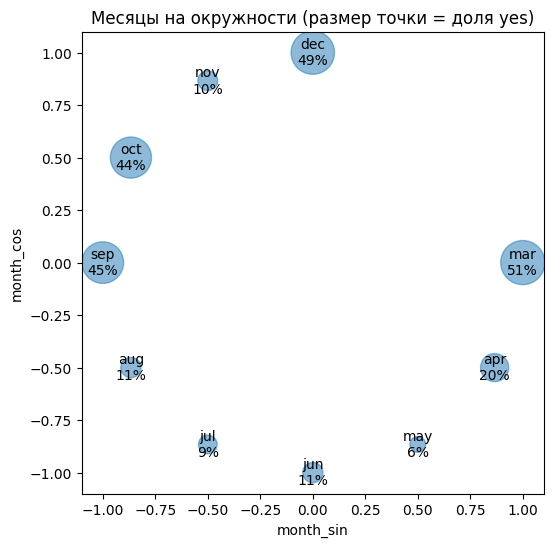

month_sin   -0.021
month_cos    0.109
dow_sin     -0.018
dow_cos     -0.012
target       1.000
Name: target, dtype: float64


In [119]:
months = df.groupby('month').agg(sin=('month_sin', 'first'),
                                 cos=('month_cos', 'first'),
                                 доля_yes=('target', 'mean'))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(months['sin'], months['cos'], s=months['доля_yes'] * 2000, alpha=0.5)
for name, row in months.iterrows():
    ax.annotate(f"{name}\n{row['доля_yes']:.0%}", (row['sin'], row['cos']), ha='center', va='center')
ax.set_xlabel('month_sin')
ax.set_ylabel('month_cos')
ax.set_title('Месяцы на окружности (размер точки = доля yes)')
ax.set_aspect('equal')
plt.show()

print(df[['month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'target']].corr()['target'].round(3))

Месяцы расположились на окружности как на циферблате (декабрь вверху, март справа, июнь внизу, сентябрь слева).

**Связь с целевой переменной слабая:** корреляция `month_cos` с `target` 0.11, остальных — около нуля. Причина видна на графике: месяцы с высокой долей `yes` (март 51%, сентябрь 45%, октябрь 44%, декабрь 49%) **не соседствуют** на окружности, а разбросаны по ней. Различия между месяцами вызваны не сезонностью, а числом звонков и экономическим периодом (раздел 4.5). Циклическое кодирование эффективно, когда зависимость плавно меняется по кругу (например, температура по месяцам), а здесь это не так.

Для дня недели связь тоже слабая (корреляции около нуля), что согласуется с разделом 4.2.
**Январь и февраль отсутствуют в данных:** банк не проводил звонков в эти месяцы (за весь период май 2008 – ноябрь 2010). Окружность всё равно делится на 12 частей, чтобы расстояния соответствовали реальному календарю: между декабрём и мартом остаётся место для двух отсутствующих месяцев. Если в будущем появится звонок в январе, циклическое кодирование поместит его между декабрём и мартом, тогда как one-hot кодировщик не знал бы такой категории. Для дня недели период равен 5, так как звонки бывают только в рабочие дни, и после пятницы следующий рабочий день — понедельник.

**Вывод:** циклические признаки реализованы корректно, но для этих данных, вероятно, one-hot кодирование месяца окажется полезнее. Сравним оба варианта на кросс-валидации в разделе 11.

### 8.7 Итоги конструирования признаков

Каждый новый признак — гипотеза, которая проверяется в три шага: (1) связь с целевой переменной; (2) не дублирует ли признак уже существующие; (3) улучшает ли он качество модели на кросс-валидации (раздел 11).

| Признак | Связь с целевой переменной | Дублирование |
|---|---|---|
| `was_contacted` | сильная: 26.6% против 8.8% | полностью совпадает с `poutcome ≠ nonexistent` |
| `age_group` | сильная: 21.0% / 10.0% / 45.5% | частично: студенты и пенсионеры уже выделены в `job` |
| `missing_count` | умеренная: 12.7% против 7–10% | частично: основной вклад даёт пропуск в `default` |
| `low_rate_period` | сильная: 24.5% против 4.8% | частично: информация есть в `euribor3m` |
| `month_sin/cos`, `dow_sin/cos` | слабая (корреляция ≤ 0.11) | — |

**Вывод.** Четыре признака сильно связаны с целевой переменной, что подтверждает наблюдения разведочного анализа. Однако большая часть этой информации уже содержится в исходных признаках, поэтому прирост качества модели может быть небольшим. Циклическое кодирование показало, что различия между месяцами вызваны не сезонностью: месяцы с высокой долей `yes` не соседствуют на окружности. Окончательное решение о включении признаков в модель примем по результатам кросс-валидации в разделе 11.

## 9. Разбиение на обучающую и тестовую выборки
**Из признаков исключаются:**
- `y`, `target` — целевая переменная;
- `duration` — утечка: длительность известна только после звонка;
- `pdays` — служебное значение 999 ненадёжно, признак заменён на `was_contacted`

**Параметры разбиения:**
- `test_size=0.2` — 80% данных на обучение, 20% на тест;
- `stratify=y` — доля `yes` в обеих выборках совпадает с долей во всех данных (обязательно при дисбалансе классов);
- `random_state=42` — фиксированное случайное разбиение, чтобы результат воспроизводился при повторном запуске.

In [120]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['y', 'target', 'duration', 'pdays'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)
print(f"Доля yes: все данные {y.mean():.2%}, train {y_train.mean():.2%}, test {y_test.mean():.2%}")

Обучающая выборка: (32940, 26)
Тестовая выборка: (8236, 26)
Доля yes: все данные 11.27%, train 11.27%, test 11.27%


In [121]:
for seed in [0, 1, 42]:
    _, _, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    print(f"Без стратификации, random_state={seed}: train {y_tr.mean():.2%}, test {y_te.mean():.2%}")

Без стратификации, random_state=0: train 11.15%, test 11.74%
Без стратификации, random_state=1: train 11.28%, test 11.19%
Без стратификации, random_state=42: train 11.14%, test 11.79%


После разбиения: обучающая выборка — 32 940 объектов, тестовая — 8 236, 26 признаков. Со стратификацией доля `yes` одинакова во всех частях — **11.27%**.

Без стратификации доля `yes` в тестовой выборке зависит от случайности: например, при `random_state=42` она составляет 11.79% против 11.14% в обучающей. На наших объёмах различие небольшое, но стратификация исключает его полностью, и оценка качества на тесте не зависит от того, насколько «удачно» легли редкие положительные примеры.

**Ограничение.** Данные упорядочены по времени (2008–2010), а случайное разбиение смешивает периоды: модель обучается на звонках из всех периодов, включая более поздние, чем часть тестовых. Это возможный источник оптимистичной оценки; подробнее — в разделе 12.

## 10. Baseline

**Baseline** — константная модель, которая всегда предсказывает самый частый класс (`no`) и не использует признаки (`DummyClassifier(strategy='most_frequent')`). Её качество — точка отсчёта: любая полезная модель должна её превзойти. Baseline обучается на обучающей выборке и оценивается на тестовой по всем метрикам, выбранным в разделе 1.

In [122]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

y_pred = dummy.predict(X_test)                 # предсказанный класс: 0 или 1
y_proba = dummy.predict_proba(X_test)[:, 1]    # предсказанная вероятность класса 1

baseline = pd.Series({
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, zero_division=0),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
    'roc_auc': roc_auc_score(y_test, y_proba),
}).round(4)
baseline

,0
accuracy,0.8873
precision,0.0000
recall,0.0000
f1,0.0000
roc_auc,0.5000


In [123]:
pd.DataFrame(confusion_matrix(y_test, y_pred),
             index=['на самом деле: no', 'на самом деле: yes'],
             columns=['предсказано: no', 'предсказано: yes'])

,предсказано: no,предсказано: yes
на самом деле: no,7308,0
на самом деле: yes,928,0


| Метрика | Baseline |
|---|---|
| accuracy | **0.8873** |
| precision | 0.0000 |
| recall | 0.0000 |
| F1 | 0.0000 |
| ROC-AUC | **0.5000** |

Матрица ошибок: все 7 308 клиентов `no` угаданы, а все 928 клиентов `yes` пропущены — модель не нашла ни одного клиента, готового открыть вклад.

**Интерпретация.**
- **Accuracy 0.887** при полной бесполезности модели — наглядное подтверждение того, что accuracy при дисбалансе классов вводит в заблуждение (раздел 1.4).
- **Recall и F1 равны 0**: модель не находит положительный класс.
- **ROC-AUC 0.5**: всем клиентам присвоена одинаковая вероятность, модель не различает их — качество ранжирования на уровне случайного.

**Планка для модели:** ROC-AUC выше 0.5 и F1 выше 0. Accuracy модели сравниваем с 0.887: модель с accuracy ниже этого значения хуже константного прогноза.

## 11. Пайплайн и модель



**Предобработка (по решениям разделов 3–8):**

| Группа признаков | Обработка | Обоснование |
|---|---|---|
| числовые | медиана для пропусков → `StandardScaler` | пропусков нет, медиана — на случай новых данных (раздел 6.7); масштабирование нужно логистической регрессии |
| `campaign` | медиана → $\log(1+x)$ → `StandardScaler` | сильная правосторонняя асимметрия (раздел 3.6) |
| категориальные | отдельная категория `missing` → one-hot | пропуски информативны (раздел 6); категории без порядка |

### 11.1 Списки признаков

Распределяем все 26 признаков из `X_train` по трём группам с разной обработкой.

In [124]:
num_features = ['age', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
                'euribor3m', 'nr.employed', 'was_contacted', 'missing_count',
                'low_rate_period', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos']
log_features = ['campaign']
cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                'contact', 'month', 'day_of_week', 'poutcome', 'age_group']

print('Всего признаков в списках:', len(num_features) + len(log_features) + len(cat_features))
print('Столбцов в X_train:', X_train.shape[1])

Всего признаков в списках: 26
Столбцов в X_train: 26


### 11.2 Сборка пайплайна

Для каждой группы признаков свой мини-конвейер обработки; `ColumnTransformer` применяет их к соответствующим столбцам и склеивает результат. В конце итогового пайплайна стоит логистическая регрессия.

In [125]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression

# Линия 1: числовые признаки
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

# Линия 2: campaign — с логарифмом
log_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler()),
])

# Линия 3: категориальные признаки
cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encode', OneHotEncoder(handle_unknown='ignore')),
])

# Сортировочный пункт: какие столбцы на какую линию
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_features),
    ('log', log_pipe, log_features),
    ('cat', cat_pipe, cat_features),
])

# Итоговый конвейер: предобработка + модель
model = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000)),
])

### 11.3 Что делает предобработка

Чтобы увидеть результат работы `ColumnTransformer`, применим его к обучающей выборке отдельно от модели.

In [126]:
X_train_prepared = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()

print('До предобработки:', X_train.shape)
print('После предобработки:', X_train_prepared.shape)

pd.DataFrame(X_train_prepared[:3], columns=feature_names).iloc[:, [0, 14, 15, 16, 17]].round(2)

До предобработки: (32940, 26)
После предобработки: (32940, 70)


,num__age,log__campaign,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur
0,-1.53,-0.04,0.0,0.0,0.0
1,-0.77,-0.87,0.0,1.0,0.0
2,-0.67,-0.87,0.0,0.0,0.0


После предобработки **26 исходных признаков превратились в 70 столбцов**: числовые признаки остались по одному столбцу (масштабированные), а каждый категориальный признак развернулся в столько столбцов, сколько у него категорий (включая `missing`). Например, `age` после масштабирования принимает значения около нуля (−1.53 — заметно моложе среднего), а профессия представлена столбцами `cat__job_admin.`, `cat__job_blue-collar` и т. д. со значениями 0 и 1.

### 11.4 Кросс-валидация на обучающей выборке

Оцениваем модель на 5 фолдах обучающей выборки со стратификацией. На каждом фолде пайплайн обучается заново только на 4/5 данных и проверяется на оставшейся 1/5. Тестовая выборка не используется.

In [127]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')

print('ROC-AUC по фолдам:', scores.round(4))
print(f'Среднее: {scores.mean():.4f} ± {scores.std():.4f}')

ROC-AUC по фолдам: [0.7961 0.7831 0.7803 0.7956 0.7879]
Среднее: 0.7886 ± 0.0064


### 11.5 Обучение и оценка на тестовой выборке

Обучаем пайплайн на всей обучающей выборке и один раз оцениваем на тестовой, по тем же метрикам, что и baseline.

In [128]:
model.fit(X_train, y_train)

y_pred_lr = model.predict(X_test)
y_proba_lr = model.predict_proba(X_test)[:, 1]

def metrics(y_true, y_pred, y_proba):
    """Все метрики раздела 1 для одной модели."""
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'roc_auc': roc_auc_score(y_true, y_proba),
    }

pd.DataFrame({
    'baseline': metrics(y_test, y_pred, y_proba),
    'логистическая регрессия': metrics(y_test, y_pred_lr, y_proba_lr),
}).round(4)

,baseline,логистическая регрессия
accuracy,0.8873,0.8979
precision,0.0000,0.6465
recall,0.0000,0.2069
f1,0.0000,0.3135
roc_auc,0.5000,0.8000


In [129]:
pd.DataFrame(confusion_matrix(y_test, y_pred_lr),
             index=['на самом деле: no', 'на самом деле: yes'],
             columns=['предсказано: no', 'предсказано: yes'])

,предсказано: no,предсказано: yes
на самом деле: no,7203,105
на самом деле: yes,736,192


| Метрика | Baseline | Логистическая регрессия |
|---|---|---|
| accuracy | 0.887 | 0.898 |
| precision | 0.000 | 0.647 |
| recall | 0.000 | 0.207 |
| F1 | 0.000 | 0.314 |
| **ROC-AUC** | 0.500 | **0.800** |

**Модель значительно лучше baseline.** ROC-AUC на тесте **0.800** (на кросс-валидации 0.789 — оценки согласуются, переобучения нет). Модель хорошо **сортирует** клиентов: среди 10% клиентов с наибольшей предсказанной вероятностью вклад открывают **49.5%** — в 4.4 раза больше, чем в среднем (11.3%). Для банка это означает, что при обзвоне по списку модели каждый второй звонок из первой десятой части будет успешным.

**Recall низкий (0.207)**: при пороге 0.5 модель находит только 192 из 928 клиентов, открывших вклад. Причина — дисбаланс классов: модель редко бывает уверена в `yes` больше чем на 50%. Зато когда она говорит `yes`, она права в 65% случаев (precision). Порог 0.5 не обязателен: банк может звонить по списку, отсортированному по вероятности, сколько позволяют ресурсы. Способы повысить recall рассмотрим в разделе 11B (обработка дисбаланса классов).

Accuracy выросла незначительно (с 0.887 до 0.898), что ещё раз показывает её непригодность для этой задачи.

### 11.6 Качество ранжирования

In [130]:
top10 = np.argsort(-y_proba_lr)[:len(y_test) // 10]
print(f"Доля yes среди 10% клиентов с наибольшей вероятностью: {y_test.values[top10].mean():.1%}")
print(f"Доля yes в среднем по тесту: {y_test.mean():.1%}")

Доля yes среди 10% клиентов с наибольшей вероятностью: 49.5%
Доля yes в среднем по тесту: 11.3%


### 11.8 Сравнение стратегий заполнения пропусков и флаги пропусков (доп. +1, +1)

Сравниваем на кросс-валидации три стратегии для категориальных признаков:
1. **мода** — пропуск заменяется самой частой категорией;
2. **мода + флаги** — то же, плюс для каждого признака с пропусками добавляется столбец 0/1 «значение было пропущено»
3. **отдельная категория** — пропуск становится категорией `missing` (текущий вариант).

Сравнение вариантов 1 и 2 показывает, помогают ли флаги пропусков. Все варианты различаются только шагом заполнения; остальной пайплайн одинаков.

In [131]:
from sklearn.base import clone

strategies = {
    'мода': SimpleImputer(strategy='most_frequent'),
    'мода + флаги': SimpleImputer(strategy='most_frequent', add_indicator=True),
    'отдельная категория': SimpleImputer(strategy='constant', fill_value='missing'),
}

for name, imputer in strategies.items():
    m = clone(model).set_params(prep__cat__impute=imputer)
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f'{name}: ROC-AUC {s.mean():.4f} ± {s.std():.4f}')

мода: ROC-AUC 0.7890 ± 0.0061
мода + флаги: ROC-AUC 0.7885 ± 0.0065
отдельная категория: ROC-AUC 0.7886 ± 0.0064


In [132]:
check = X_train.assign(target=y_train,
                       default_missing=X_train['default'].isna())
check.groupby(['low_rate_period', 'default_missing'])['target'].mean().round(3)

low_rate_period  default_missing
0                False              0.051
                 True               0.044
1                False              0.259
                 True               0.100
Name: target, dtype: float64

| Стратегия | ROC-AUC (CV) |
|---|---|
| мода | 0.7890 ± 0.0061 |
| мода + флаги | 0.7885 ± 0.0065 |
| отдельная категория | 0.7886 ± 0.0064 |

**Различия в пределах погрешности** . Флаги пропусков качество не улучшили.

**Это не подтверждает ожидание из раздела 6.7**, что мода будет хуже. Объяснение: пропуски в `default` относятся к типу MAR — они зависят от возраста, профессии и периода (раздел 6.2). Поэтому информацию, которую несёт факт пропуска, модель получает из других признаков. Например, в период высоких ставок доля `yes` почти не зависит от пропуска (4.4% против 5.1%), а основное различие объясняется периодом, который модель видит через экономические признаки.

**Решение:** оставляем отдельную категорию: качество одинаковое, а вариант сохраняет информацию о пропуске явно и не требует лишних столбцов.

### 11.9 Обработка дисбаланса классов (доп. +2)

Классы несбалансированы (11% `yes`), из-за чего модель редко предсказывает `yes` и recall низкий (раздел 11.5). Сравниваем три способа :
1. **веса классов** (`class_weight='balanced'`) — ошибки на редком классе штрафуются сильнее, пропорционально его редкости; данные не меняются;
- undersampling немного хуже по ROC-AUC: он выбрасывает большую часть объектов `no`, и модель обучается на меньшем объёме данных;
- oversampling многократно копирует редкие объекты, что может приводить к переобучению на копиях;

Сравниваем по ROC-AUC, precision, recall и F1 на кросс-валидации.

In [133]:
!pip install -q -U imbalanced-learn

In [134]:
from sklearn.model_selection import cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

variants = {
    'без обработки': clone(model),
    'веса классов': clone(model).set_params(clf__class_weight='balanced'),
    'undersampling': ImbPipeline([('prep', clone(preprocessor)),
                                  ('sampler', RandomUnderSampler(random_state=42)),
                                  ('clf', LogisticRegression(max_iter=1000))]),
    'oversampling': ImbPipeline([('prep', clone(preprocessor)),
                                 ('sampler', RandomOverSampler(random_state=42)),
                                 ('clf', LogisticRegression(max_iter=1000))]),
}

results = {}
for name, m in variants.items():
    r = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=['roc_auc', 'precision', 'recall', 'f1'])
    results[name] = {metric: r[f'test_{metric}'].mean()
                     for metric in ['roc_auc', 'precision', 'recall', 'f1']}

pd.DataFrame(results).T.round(4)

,roc_auc,precision,recall,f1
без обработки,0.7886,0.6674,0.2282,0.3399
веса классов,0.7893,0.3535,0.6219,0.4507
undersampling,0.7872,0.3468,0.6246,0.4459
oversampling,0.7891,0.3529,0.6217,0.4501


| Способ | ROC-AUC | Precision | Recall | F1 |
|---|---|---|---|---|
| без обработки | 0.7886 | **0.667** | 0.228 | 0.340 |
| веса классов | **0.7893** | 0.354 | 0.622 | **0.451** |
| undersampling | 0.7872 | 0.347 | 0.625 | 0.446 |
| oversampling | 0.7891 | 0.353 | 0.622 | 0.450 |

**Все три способа обработки дисбаланса почти одинаково меняют поведение модели:** recall вырастает с 0.23 до 0.62 (модель находит почти в 3 раза больше клиентов, готовых открыть вклад), precision падает с 0.67 до 0.35 (больше лишних звонков), F1 растёт с 0.34 до 0.45.

**ROC-AUC при этом почти не меняется.** Это ожидаемо: обработка дисбаланса в основном сдвигает предсказанные вероятности вверх, что эквивалентно снижению порога, а порядок клиентов по вероятности (который и измеряет ROC-AUC) остаётся прежним.

**Сравнение способов:**
- undersampling немного хуже по ROC-AUC: он выбрасывает данные — модель обучается на 7.4 тыс. объектов вместо 33 тыс.;
- oversampling копирует редкие объекты, что увеличивает выборку до 58 тыс. и может приводить к переобучению на копиях;
- веса классов дают лучший результат без изменения данных.

**Решение:** используем **веса классов** — самый простой способ, без потери и дублирования данных, с лучшими ROC-AUC и F1. Выбор между исходной моделью и моделью с весами — это выбор между precision и recall: если для банка дороже упущенный клиент, чем лишний звонок, предпочтительна модель с весами.

### 11.10 Проверка новых признаков

Решающая проверка признаков из раздела 8: сравниваем качество модели с новыми признаками и без них, а также два способа кодирования месяца и дня недели.

In [135]:
base_num = ['age', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed']
base_cat = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']
cyclic = ['month_sin', 'month_cos', 'dow_sin', 'dow_cos']

def with_columns(num_cols, cat_cols):
    """Копия модели, использующая только указанные признаки."""
    m = clone(model)
    m.set_params(prep__transformers=[('num', numeric_pipe, num_cols),
                                     ('log', log_pipe, log_features),
                                     ('cat', cat_pipe, cat_cols)])
    return m

feature_sets = {
    'исходные признаки': with_columns(base_num, base_cat),
    'все признаки': with_columns(num_features, cat_features),
    'месяц и день только циклические': with_columns(
        num_features, [c for c in cat_features if c not in ['month', 'day_of_week']]),
    'месяц и день только one-hot': with_columns(
        [c for c in num_features if c not in cyclic], cat_features),
}

for name, m in feature_sets.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f'{name}: {s.mean():.4f} ± {s.std():.4f}')

исходные признаки: 0.7887 ± 0.0069
все признаки: 0.7886 ± 0.0064
месяц и день только циклические: 0.7828 ± 0.0073
месяц и день только one-hot: 0.7885 ± 0.0065


| Набор признаков | ROC-AUC (CV) |
|---|---|
| исходные признаки | 0.7887 ± 0.0069 |
| все признаки (с новыми из раздела 8) | 0.7886 ± 0.0064 |
| месяц и день только циклические | **0.7828** ± 0.0073 |
| месяц и день только one-hot | 0.7885 ± 0.0065 |

**Новые признаки не улучшили модель.** Это подтверждает вывод раздела 8.7: информация из них уже содержится в исходных признаках (`poutcome`, `job`, `euribor3m`).

**Циклическое кодирование хуже one-hot** (0.783 против 0.789): как показал раздел 8.6, различия между месяцами не сезонные, а one-hot позволяет каждому месяцу иметь собственный вес. Поэтому в модели месяц и день недели кодируются one-hot.

Новые признаки оставляем в итоговой модели: они не ухудшают качество и делают явными закономерности, найденные в анализе. Отказ от них также был бы обоснованным решением.

### 11.11 Итоговая модель

Итоговая модель: логистическая регрессия с весами классов, пропуски в категориях — отдельная категория. Обучаем на всей обучающей выборке и оцениваем на тестовой.

In [136]:
final_model = clone(model).set_params(clf__class_weight='balanced')
final_model.fit(X_train, y_train)

y_pred_final = final_model.predict(X_test)
y_proba_final = final_model.predict_proba(X_test)[:, 1]

print(pd.DataFrame({
    'baseline': metrics(y_test, y_pred, y_proba),
    'логрегрессия': metrics(y_test, y_pred_lr, y_proba_lr),
    'логрегрессия + веса классов': metrics(y_test, y_pred_final, y_proba_final),
}).round(4))

pd.DataFrame(confusion_matrix(y_test, y_pred_final),
             index=['на самом деле: no', 'на самом деле: yes'],
             columns=['предсказано: no', 'предсказано: yes'])

           baseline  логрегрессия  логрегрессия + веса классов
accuracy     0.8873        0.8979                       0.8301
precision    0.0000        0.6465                       0.3591
recall       0.0000        0.2069                       0.6466
f1           0.0000        0.3135                       0.4617
roc_auc      0.5000        0.8000                       0.7998


,предсказано: no,предсказано: yes
на самом деле: no,6237,1071
на самом деле: yes,328,600


| Метрика | Baseline | Логрегрессия | Логрегрессия + веса классов |
|---|---|---|---|
| accuracy | 0.887 | 0.898 | 0.830 |
| precision | 0.000 | 0.647 | 0.359 |
| recall | 0.000 | 0.207 | **0.647** |
| F1 | 0.000 | 0.314 | **0.462** |
| ROC-AUC | 0.500 | 0.800 | 0.800 |

Итоговая модель находит **600 из 928** клиентов, открывших вклад (recall 0.65), ценой 1 071 лишнего звонка. Accuracy снизилась (0.83 < 0.887 у baseline), но для этой задачи accuracy не показательна: модель с весами предсказывает `yes` гораздо чаще, поэтому чаще ошибается на большом классе `no`, зато находит в 3 раза больше нужных клиентов. ROC-AUC на тесте 0.80 совпадает с кросс-валидацией (0.789), признаков переобучения нет.

## 12. Анализ утечки



### 12.1 Признаки и риск утечки

| Признак | Известен до звонка? | Риск утечки | Решение |
|---|---|---|---|
| `duration` | **нет**: длительность известна только после звонка, когда исход уже определён | **прямая утечка** | исключён |
| `campaign` | частично: число звонков в текущей кампании, **включая последний**; в начале кампании итоговое значение неизвестно | умеренный | оставлен; корректен, если модель применяется перед каждым очередным звонком (номер звонка известен) |
| `emp.var.rate`, `nr.employed` | частично: квартальные показатели публикуются с задержкой; в момент звонка значение текущего квартала может быть ещё неизвестно | умеренный | оставлены; в реальном применении нужно использовать последнее опубликованное значение |
| `euribor3m`, `cons.price.idx`, `cons.conf.idx` | да: дневные и месячные показатели доступны | низкий | оставлены |
| `previous`, `poutcome`, `pdays` | да: относятся к прошлым кампаниям | нет | оставлены (`pdays` заменён `was_contacted`) |
| признаки клиента (`age`, `job`, …) | да | нет | оставлены |
| `month`, `day_of_week`, `contact` | да: планируются до звонка | нет | оставлены |

**Утечка через предобработку исключена:**
- все статистики (медианы, масштабирование, категории one-hot) вычисляются внутри пайплайна только на обучающей выборке;
- дубликаты удалены до разбиения (раздел 7.7);
- сэмплирование при обработке дисбаланса выполняется внутри пайплайна только на обучающих фолдах (раздел 11.9);

### 12.2 Эксперимент 1: что даёт утечка через `duration`

Добавим `duration` в модель и посмотрим, как изменится качество.

In [137]:
X_train_dur = X_train.join(df['duration'])     # добавляем duration обратно по индексу строк
X_test_dur = X_test.join(df['duration'])

model_dur = clone(model).set_params(prep__transformers=[
    ('num', numeric_pipe, num_features + ['duration']),
    ('log', log_pipe, log_features),
    ('cat', cat_pipe, cat_features),
])
model_dur.fit(X_train_dur, y_train)

print(f"ROC-AUC без duration: {roc_auc_score(y_test, y_proba_lr):.4f}")
print(f"ROC-AUC с duration:   {roc_auc_score(y_test, model_dur.predict_proba(X_test_dur)[:, 1]):.4f}")

ROC-AUC без duration: 0.8000
ROC-AUC с duration:   0.9390


С `duration` ROC-AUC вырастает с **0.80 до 0.94**. Такой скачок от одного признака — характерный признак утечки: «слишком хорошее» качество . Модель с `duration` фактически использует информацию об исходе разговора. На практике она бесполезна: в момент решения о звонке его длительность неизвестна, и предсказать для нового клиента ничего нельзя.

### 12.3 Эксперимент 2: проверка на будущих данных

Данные упорядочены по времени (май 2008 — ноябрь 2010). Случайное разбиение смешивает периоды: модель обучается в том числе на звонках, сделанных позже части тестовых.

Проверим, как модель работает в реалистичном сценарии: обучаем на первых 80% звонков по времени, тестируем на последних 20%.

In [138]:
X_sorted = X.sort_index()                  # строки в исходном порядке файла = хронологический порядок
y_sorted = y.loc[X_sorted.index]
cut = int(len(X_sorted) * 0.8)

X_past, X_future = X_sorted.iloc[:cut], X_sorted.iloc[cut:]
y_past, y_future = y_sorted.iloc[:cut], y_sorted.iloc[cut:]

print(f"Доля yes: прошлое {y_past.mean():.1%}, будущее {y_future.mean():.1%}")
print(f"Ставка Euribor: прошлое {X_past['euribor3m'].min():.2f}–{X_past['euribor3m'].max():.2f}, "
      f"будущее {X_future['euribor3m'].min():.2f}–{X_future['euribor3m'].max():.2f}")

model_time = clone(model).fit(X_past, y_past)
print(f"ROC-AUC при случайном разбиении: {roc_auc_score(y_test, y_proba_lr):.4f}")
print(f"ROC-AUC на будущих данных:       {roc_auc_score(y_future, model_time.predict_proba(X_future)[:, 1]):.4f}")

Доля yes: прошлое 6.4%, будущее 30.8%
Ставка Euribor: прошлое 1.30–5.04, будущее 0.63–1.30
ROC-AUC при случайном разбиении: 0.8000
ROC-AUC на будущих данных:       0.7479


| Сценарий | ROC-AUC |
|---|---|
| случайное разбиение (раздел 11) | 0.800 |
| обучение на прошлом, проверка на будущем | **0.748** |

На будущих данных качество **ниже**. Причина — сдвиг распределения: последние 20% звонков пришлись на период низких ставок (Euribor 0.63–1.30%), которых модель почти не видела при обучении (1.30–5.05%), а доля `yes` в этот период — 30.8% против 6.4% в обучающей части. Модель обучалась в одной экономической ситуации, а применяется в другой.

**Вывод:** оценка 0.80 при случайном разбиении **оптимистична** для реального применения, где модель всегда предсказывает будущее. Более реалистичная оценка — около 0.75. Случайное разбиение со стратификацией выполнено по требованию задания, но для внедрения модели следовало бы использовать разбиение по времени и регулярно переобучать модель на свежих данных.

### 12.4 Выводы

1. **`duration` — прямая утечка**: известна только после звонка; её добавление поднимает ROC-AUC с 0.80 до 0.94. Признак исключён.
2. **Временная утечка через случайное разбиение**: при проверке на будущих звонках ROC-AUC снижается до 0.75 из-за смены экономического периода. Экономические признаки делают модель зависимой от периода, в котором она обучена.
3. **Пограничные признаки**: `campaign` (включает последний звонок) и квартальные экономические показатели (публикуются с задержкой) корректны только при определённой схеме применения модели.
4. **Утечка через предобработку исключена** пайплайном, удалением дубликатов до разбиения и сэмплированием внутри обучающих фолдов.

## 13. Выводы

### Что удалось узнать о данных

1. **Данные требуют аккуратной подготовки.** Пропуски скрыты строкой `"unknown"` (до 21% в `default`), служебное значение 999 в `pdays` занимает 96% столбца и противоречит `previous` у 4 110 клиентов, найдено 12 полных дубликатов. Ошибок в значениях (невозможных величин) нет.
2. **Сильный дисбаланс классов**: вклад открывают 11.3% клиентов, поэтому accuracy непригодна; основная метрика — ROC-AUC.
3. **Самые сильные факторы успеха:**
   - прошлый опыт клиента: при успехе прошлой кампании вклад открывают 65% клиентов;
   - экономический период: при ставке Euribor до 1% — 46%, выше 4% — менее 5%;
   - возраст (нелинейно): клиенты старше 60 лет — 46%, до 25 лет — 21%, 30–50 лет — 8–10%;
   - число звонков: с ростом числа звонков в кампании доля успеха падает с 13% до 4%.
4. **Часть связей опосредована скрытыми факторами**: разница между мобильными и стационарными телефонами во многом объясняется периодом звонка; экономические признаки сильно коррелируют между собой (до 0.97).
5. **`duration` — утечка**: признак сильнее всех связан с целевой переменной, но известен только после звонка.
6. **Неустранимая ошибка**: в 237 группах клиенты с одинаковыми признаками дали разные ответы — часть решения клиента определяется факторами, которых нет в данных.

### Что получилось с моделью

| Модель | ROC-AUC (тест) | Recall | F1 |
|---|---|---|---|
| Baseline | 0.500 | 0.000 | 0.000 |
| Логистическая регрессия | 0.800 | 0.207 | 0.314 |
| Логистическая регрессия + веса классов | 0.800 | 0.647 | 0.462 |

- Модель значительно лучше baseline: среди 10% клиентов с наибольшей предсказанной вероятностью вклад открывают 49.5% — в 4.4 раза больше среднего.
- Веса классов повышают recall с 0.21 до 0.65 при неизменном ROC-AUC; выбор между вариантами зависит от соотношения стоимости звонка и упущенного клиента.
- Стратегия заполнения пропусков и флаги пропусков на качество не повлияли (пропуски типа MAR, информация есть в других признаках).
- Новые признаки не улучшили линейную модель; циклическое кодирование месяца хуже one-hot, так как различия между месяцами не сезонные.

### Чего ожидать от моделей дальше

1. **Нелинейные модели** (деревья решений, случайный лес, градиентный бустинг — лекции 5–6) могут улучшить качество: они сами находят нелинейности (как U-образную зависимость от возраста) и взаимодействия признаков, а также устойчивы к мультиколлинеарности и выбросам.
2. **Потолок качества ограничен**: из-за неустранимой ошибки и отсутствия информации о финансовом положении клиента ожидать ROC-AUC, близкий к 1, не стоит (без утечки).
3. **Главный риск — смена периода**: при проверке на будущих данных качество падает с 0.80 до 0.75. Для практического применения нужны разбиение по времени при оценке и регулярное переобучение.
4. **Подбор порога** классификации под стоимость ошибок банка может дать больше практической пользы, чем усложнение модели.